In [2]:
from pathlib import Path

import pandas as pd
from sklearn.impute import KNNImputer

In [3]:
FEATURES = ["nevents", "ndays_act", "ncontent", "nforum_posts"]
TARGET = "Engagement_Level"

In [4]:
def find_project_root(start=None):
    """Walk upwards until a folder containing configs/base.yaml is found."""
    start = Path(start or Path.cwd()).resolve()
    for folder in [start, *start.parents]:
        if (folder / "configs" / "base.yaml").exists():
            return folder
    raise FileNotFoundError(f"Could not find configs/base.yaml above {start}")

In [5]:

PROJECT_ROOT = find_project_root()
train = pd.read_csv(PROJECT_ROOT / "data" / "processed" / "train.csv")

In [6]:
print("Project root:", PROJECT_ROOT)
print("train:", train.shape)
print(train[FEATURES].isna().sum())

Project root: D:\student_engagement_twin
train: (21328, 5)
nevents          3643
ndays_act        2246
ncontent            0
nforum_posts    14526
dtype: int64


the KNN imputer

In [7]:
N_NEIGHBORS = 5   # we'll move this into base.yaml later

imputer = KNNImputer(n_neighbors=N_NEIGHBORS)
imputer.fit(train[FEATURES])

train_imputed = pd.DataFrame(imputer.transform(train[FEATURES]), columns=FEATURES)
train_imputed[TARGET] = train[TARGET].values


In [8]:
print("NaNs before:", train[FEATURES].isna().sum().sum())
print("NaNs after :", train_imputed[FEATURES].isna().sum().sum())
print(train_imputed.head())

NaNs before: 20415
NaNs after : 0
   nevents  ndays_act  ncontent  nforum_posts  Engagement_Level
0    105.0        5.0       7.0           1.0                 0
1    930.0       13.0      46.0           1.8                 0
2    355.8        1.0     100.0           2.8                 0
3   4059.0        8.0     100.0           3.2                 1
4     29.0        3.0       7.0           1.0                 0


In [9]:
# 1. Counts must be whole numbers
train_imputed[FEATURES] = train_imputed[FEATURES].round().astype(int)

In [10]:
# 2. Where were the gaps in the ORIGINAL train data?
mask = train[FEATURES].isna()

In [11]:
# 3. For the "random" strategy: the rate per column
miss_rates = mask.mean()
print("Missing rates (train):")
print(miss_rates.round(4))

Missing rates (train):
nevents         0.1708
ndays_act       0.1053
ncontent        0.0000
nforum_posts    0.6811
dtype: float64


In [12]:
# 4. For the "from_column" strategy: 0/1 flag columns
flags = mask.astype(int).add_suffix("_missing")
train_with_flags = pd.concat([train_imputed, flags], axis=1)

print("\nColumns:", train_with_flags.columns.tolist())
print(train_with_flags.head())
print("\nFlag column sums (number of missing cells):")
print(flags.sum())


Columns: ['nevents', 'ndays_act', 'ncontent', 'nforum_posts', 'Engagement_Level', 'nevents_missing', 'ndays_act_missing', 'ncontent_missing', 'nforum_posts_missing']
   nevents  ndays_act  ncontent  nforum_posts  Engagement_Level  \
0      105          5         7             1                 0   
1      930         13        46             2                 0   
2      356          1       100             3                 0   
3     4059          8       100             3                 1   
4       29          3         7             1                 0   

   nevents_missing  ndays_act_missing  ncontent_missing  nforum_posts_missing  
0                0                  0                 0                     0  
1                0                  0                 0                     1  
2                1                  0                 0                     1  
3                0                  0                 0                     1  
4                0            

 restore the gaps in fake data

Fake data comes out of a generator with no NaNs. We need a function that puts them back. Let’s build and test both versions now, using the real training data as a stand-in for “fake data” so we don’t need a generator yet.

In [13]:
import numpy as np

SEED = 42


def restore_random(df, miss_rates, seed=SEED):
    """Put NaNs back at the training missing rate for each column."""
    rng = np.random.default_rng(seed)
    out = df[FEATURES].astype(float).copy()
    for col in FEATURES:
        hide = rng.random(len(out)) < miss_rates[col]
        out.loc[hide, col] = np.nan
    return out


In [14]:
def restore_from_column(df):
    """Put NaNs back wherever the *_missing flag is 1, then drop the flags."""
    out = df[FEATURES].astype(float).copy()
    for col in FEATURES:
        out.loc[df[f"{col}_missing"] == 1, col] = np.nan
    return out


In [15]:
# Test both on train_with_flags (stand-in for generated data)
r1 = restore_random(train_with_flags, miss_rates)
r2 = restore_from_column(train_with_flags)

print("random      ->", (r1.isna().mean() * 100).round(2).to_dict())
print("from_column ->", (r2.isna().mean() * 100).round(2).to_dict())
print("target      ->", (miss_rates * 100).round(2).to_dict())

random      -> {'nevents': 17.12, 'ndays_act': 10.48, 'ncontent': 0.0, 'nforum_posts': 68.48}
from_column -> {'nevents': 17.08, 'ndays_act': 10.53, 'ncontent': 0.0, 'nforum_posts': 68.11}
target      -> {'nevents': 17.08, 'ndays_act': 10.53, 'ncontent': 0.0, 'nforum_posts': 68.11}


random      -> {'nevents': 17.12, 'ndays_act': 10.48, 'ncontent': 0.0, 'nforum_posts': 68.48}
from_column -> {'nevents': 17.08, 'ndays_act': 10.53, 'ncontent': 0.0, 'nforum_posts': 68.11}
target      -> {'nevents': 17.08, 'ndays_act': 10.53, 'ncontent': 0.0, 'nforum_posts': 68.11}

Build the generator input tables

create the two tables the generators will learn from, one per missingness strategy.


1. Fit a `KNNImputer` on real `train` only, then fill the NaNs.
2. Round to whole numbers, because these columns are counts.
3. `random` table: the 4 imputed features.
4. `from_column` table: the same 4 features plus a 0/1 `<feature>_missing` flag for each feature that has gaps.


In [16]:
from pathlib import Path

import pandas as pd
from sklearn.impute import KNNImputer

FEATURES = ["nevents", "ndays_act", "ncontent", "nforum_posts"]
TARGET = "Engagement_Level"
N_NEIGHBORS = 5   # to be moved into base.yaml later


def find_project_root(start=None):
    """Walk upwards until a folder containing configs/base.yaml is found."""
    start = Path(start or Path.cwd()).resolve()
    for folder in [start, *start.parents]:
        if (folder / "configs" / "base.yaml").exists():
            return folder
    raise FileNotFoundError(f"Could not find configs/base.yaml above {start}")


PROJECT_ROOT = find_project_root()
out_dir = PROJECT_ROOT / "data" / "processed"
train = pd.read_csv(out_dir / "train.csv")

# 1. Fit the imputer on train only, then fill the gaps
imputer = KNNImputer(n_neighbors=N_NEIGHBORS).fit(train[FEATURES])
imputed = pd.DataFrame(imputer.transform(train[FEATURES]), columns=FEATURES)

# 2. Counts must be whole numbers
imputed = imputed.round().astype(int)

# 3. Missingness flags, only for columns that actually have gaps
mask = train[FEATURES].isna()
flag_cols = [c for c in FEATURES if mask[c].any()]
flags = mask[flag_cols].astype(int).add_suffix("_missing")

# 4. The two generator input tables (features only, no target)
gen_random = imputed.copy()
gen_from_column = pd.concat([imputed, flags], axis=1)

gen_random.to_csv(out_dir / "gen_input_random.csv", index=False)
gen_from_column.to_csv(out_dir / "gen_input_from_column.csv", index=False)

print("Project root:", PROJECT_ROOT)
print("random      :", gen_random.shape, "| NaNs:", int(gen_random.isna().sum().sum()))
print("from_column :", gen_from_column.shape, "| NaNs:", int(gen_from_column.isna().sum().sum()))
print("from_column columns:", gen_from_column.columns.tolist())
print("Target in tables?  :", TARGET in gen_random.columns or TARGET in gen_from_column.columns)

Project root: D:\student_engagement_twin
random      : (21328, 4) | NaNs: 0
from_column : (21328, 7) | NaNs: 0
from_column columns: ['nevents', 'ndays_act', 'ncontent', 'nforum_posts', 'nevents_missing', 'ndays_act_missing', 'nforum_posts_missing']
Target in tables?  : False


All four checks passed: 21,328 rows in both tables, zero NaNs, the right columns, and no target in the tables. The generator inputs are ready.

In [19]:
import sdv
from sdv import metadata as md

print("SDV version:", sdv.__version__)
print("\nNames in sdv.metadata:")
print([n for n in dir(md) if not n.startswith("_")])

for name in ("Metadata", "SingleTableMetadata"):
    cls = getattr(md, name, None)
    if cls is not None:
        print(f"\n{name} methods containing 'detect':")
        print([m for m in dir(cls) if "detect" in m])

from sdv import single_table
print("\nNames in sdv.single_table:")
print([n for n in dir(single_table) if not n.startswith("_")])

SDV version: 2.0.0

Names in sdv.metadata:
['InvalidMetadataError', 'Metadata', 'MetadataNotFittedError', 'errors', 'metadata', 'metadata_upgrader', 'utils', 'visualization']

Metadata methods containing 'detect':
['_detect_foreign_keys_by_column_name', '_detect_from_dataframe', '_detect_from_dataframes', '_detect_relationships', '_detect_table_from_dataframe', '_log_detected_table', '_validate_table_not_detected', 'detect_from_csvs', 'detect_from_dataframes']

Names in sdv.single_table:
['CTGANSynthesizer', 'CopulaGANSynthesizer', 'DayZSynthesizer', 'GaussianCopulaSynthesizer', 'TVAESynthesizer', 'base', 'copulagan', 'copulas', 'ctgan', 'dayz', 'mixins', 'utils']


 CTGAN smoke test (5 epochs, `random` table)

check that CTGAN trains and samples on this machine before committing to the full 300-epoch run.

1. Read `gen_input_random.csv` (4 imputed features, no target).
2. Detect metadata and confirm all four columns are `numerical`.
3. Train `CTGANSynthesizer` for 5 epochs.
4. Sample 21,328 rows, the same size as the real training set.
5. Save the synthetic rows and the trained model.

**Decisions:**
- `EPOCHS = 5` is only for testing. The final run uses 300, as in the paper.
- Seed fixed for reproducibility.
- Synthetic rows are unlabeled and NaNs are not restored at this stage.

In [22]:
import time
from pathlib import Path

import numpy as np
import pandas as pd
import sdv
import torch
from sdv.metadata import Metadata
from sdv.single_table import CTGANSynthesizer

SEED = 42
EPOCHS = 5   # smoke test only; the full run uses 300
TABLE = "students"


def detect_metadata(df: pd.DataFrame) -> Metadata:
    """Detect single-table metadata using the SDV 2.0 API."""
    return Metadata.detect_from_dataframes({TABLE: df})


def find_project_root(start=None):
    """Walk upwards until a folder containing configs/base.yaml is found."""
    start = Path(start or Path.cwd()).resolve()
    for folder in [start, *start.parents]:
        if (folder / "configs" / "base.yaml").exists():
            return folder
    raise FileNotFoundError(f"Could not find configs/base.yaml above {start}")


PROJECT_ROOT = find_project_root()
real = pd.read_csv(PROJECT_ROOT / "data" / "processed" / "gen_input_random.csv")

np.random.seed(SEED)
torch.manual_seed(SEED)

print("SDV version:", sdv.__version__)
metadata = detect_metadata(real)
print(metadata.to_dict())   # all four columns should be 'numerical'

import inspect

print("CTGANSynthesizer parameters:")
print(list(inspect.signature(CTGANSynthesizer.__init__).parameters))

def unwrap(result):
    """Return a DataFrame whether SDV gave us a DataFrame or {table: DataFrame}."""
    if isinstance(result, dict):
        return result[TABLE] if TABLE in result else next(iter(result.values()))
    return result


synth = CTGANSynthesizer(metadata, epochs=EPOCHS, verbose=True)

start = time.time()
synth.fit({TABLE: real})
print(f"\nTraining time: {time.time() - start:.1f} s")

fake = unwrap(synth.sample(num_rows=len(real)))

gen_dir = PROJECT_ROOT / "artifacts" / "generators"
gen_dir.mkdir(parents=True, exist_ok=True)
fake.to_csv(gen_dir / "ctgan_random_smoke.csv", index=False)
synth.save(str(gen_dir / "ctgan_random_smoke.pkl"))

print("Real :", real.shape, "| Fake:", fake.shape)
print(fake.dtypes.to_dict())
print(fake.head())

SDV version: 2.0.0
{'tables': {'students': {'columns': {'nevents': {'sdtype': 'numerical', 'range_is_nullable': False, 'range_min': 1, 'range_max': 168896, 'decimal_places': 0}, 'ndays_act': {'sdtype': 'numerical', 'range_is_nullable': False, 'range_min': 1, 'range_max': 103, 'decimal_places': 0}, 'ncontent': {'sdtype': 'numerical', 'range_is_nullable': False, 'range_min': 4, 'range_max': 100, 'decimal_places': 0}, 'nforum_posts': {'sdtype': 'numerical', 'range_is_nullable': False, 'range_min': 1, 'range_max': 326, 'decimal_places': 0}}}}, 'relationships': [], 'METADATA_SPEC_VERSION': 'V2'}
CTGANSynthesizer parameters:
['self', 'metadata', 'enforce_min_max_values', 'enforce_rounding', 'locales', 'embedding_dim', 'generator_dim', 'discriminator_dim', 'generator_lr', 'generator_decay', 'discriminator_lr', 'discriminator_decay', 'batch_size', 'discriminator_steps', 'log_frequency', 'verbose', 'epochs', 'pac', 'enable_gpu']


d:\student_engagement_twin\.venv\Lib\site-packages\sdv\single_table\base.py:136: UserWarning: We strongly recommend saving the metadata using 'save_to_json' for replicability in future SDV versions.
  warnings.warn(
Gen. (-00.67) | Discrim. (-00.06): 100%|██████████| 5/5 [00:03<00:00,  1.26it/s]


Training time: 15.6 s
Real : (21328, 4) | Fake: (21328, 4)
{'nevents': dtype('int64'), 'ndays_act': dtype('int64'), 'ncontent': dtype('int64'), 'nforum_posts': dtype('int64')}
   nevents  ndays_act  ncontent  nforum_posts
0       97          1        13             3
1      581         16        99             1
2      360          4        13             1
3      227          5        99             1
4      509          2        30            12


 CTGAN full run (300 epochs, `random` table)

train the final CTGAN on the real training features and sample a synthetic training set of the same size (21,328 rows).

In [23]:
import time
from pathlib import Path

import numpy as np
import pandas as pd
import sdv
import torch
from sdv.metadata import Metadata
from sdv.single_table import CTGANSynthesizer

SEED = 42
EPOCHS = 300
TABLE = "students"


def find_project_root(start=None):
    """Walk upwards until a folder containing configs/base.yaml is found."""
    start = Path(start or Path.cwd()).resolve()
    for folder in [start, *start.parents]:
        if (folder / "configs" / "base.yaml").exists():
            return folder
    raise FileNotFoundError(f"Could not find configs/base.yaml above {start}")


def unwrap(result):
    """Return a DataFrame whether SDV gave us a DataFrame or {table: DataFrame}."""
    if isinstance(result, dict):
        return result[TABLE] if TABLE in result else next(iter(result.values()))
    return result


PROJECT_ROOT = find_project_root()
real = pd.read_csv(PROJECT_ROOT / "data" / "processed" / "gen_input_random.csv")

np.random.seed(SEED)
torch.manual_seed(SEED)

metadata = Metadata.detect_from_dataframes({TABLE: real})
synth = CTGANSynthesizer(metadata, epochs=EPOCHS, verbose=True)

start = time.time()
synth.fit({TABLE: real})
train_seconds = time.time() - start
print(f"\nTraining time: {train_seconds / 60:.1f} min")

fake = unwrap(synth.sample(num_rows=len(real)))

gen_dir = PROJECT_ROOT / "artifacts" / "generators"
gen_dir.mkdir(parents=True, exist_ok=True)
fake.to_csv(gen_dir / "ctgan_random.csv", index=False)
synth.save(str(gen_dir / "ctgan_random.pkl"))

print("SDV:", sdv.__version__, "| epochs:", EPOCHS, "| seed:", SEED)
print("Real :", real.shape, "| Fake:", fake.shape)
print(fake.dtypes.to_dict())
print(fake.describe().round(1))

d:\student_engagement_twin\.venv\Lib\site-packages\sdv\single_table\base.py:136: UserWarning: We strongly recommend saving the metadata using 'save_to_json' for replicability in future SDV versions.
  warnings.warn(
Gen. (-00.89) | Discrim. (+00.14): 100%|██████████| 300/300 [05:41<00:00,  1.14s/it]



Training time: 5.8 min
SDV: 2.0.0 | epochs: 300 | seed: 42
Real : (21328, 4) | Fake: (21328, 4)
{'nevents': dtype('int64'), 'ndays_act': dtype('int64'), 'ncontent': dtype('int64'), 'nforum_posts': dtype('int64')}
       nevents  ndays_act  ncontent  nforum_posts
count  21328.0    21328.0   21328.0       21328.0
mean     814.4        5.0      71.8           3.1
std     1385.8        5.1      34.9           3.7
min        1.0        1.0       4.0           1.0
25%       95.0        2.0      36.0           1.0
50%      311.5        3.0     100.0           2.0
75%      967.0        6.0     100.0           3.0
max    16401.0       56.0     100.0          38.0


TVAE full run (300 epochs, `random` table)

train the second generator (TVAE) on the same real training features and sample 21,328 synthetic rows.

In [24]:
import inspect
import time
from pathlib import Path

import numpy as np
import pandas as pd
import sdv
import torch
from sdv.metadata import Metadata
from sdv.single_table import TVAESynthesizer

SEED = 42
EPOCHS = 300
TABLE = "students"


def find_project_root(start=None):
    """Walk upwards until a folder containing configs/base.yaml is found."""
    start = Path(start or Path.cwd()).resolve()
    for folder in [start, *start.parents]:
        if (folder / "configs" / "base.yaml").exists():
            return folder
    raise FileNotFoundError(f"Could not find configs/base.yaml above {start}")


def unwrap(result):
    """Return a DataFrame whether SDV gave us a DataFrame or {table: DataFrame}."""
    if isinstance(result, dict):
        return result[TABLE] if TABLE in result else next(iter(result.values()))
    return result


PROJECT_ROOT = find_project_root()
real = pd.read_csv(PROJECT_ROOT / "data" / "processed" / "gen_input_random.csv")

np.random.seed(SEED)
torch.manual_seed(SEED)

gen_dir = PROJECT_ROOT / "artifacts" / "generators"
gen_dir.mkdir(parents=True, exist_ok=True)

metadata = Metadata.detect_from_dataframes({TABLE: real})
metadata.save_to_json(str(gen_dir / "metadata_random.json"), mode="overwrite")

print("TVAESynthesizer parameters:")
print(list(inspect.signature(TVAESynthesizer.__init__).parameters))

synth = TVAESynthesizer(metadata, epochs=EPOCHS)

start = time.time()
synth.fit({TABLE: real})
print(f"\nTraining time: {(time.time() - start) / 60:.1f} min")

fake = unwrap(synth.sample(num_rows=len(real)))

fake.to_csv(gen_dir / "tvae_random.csv", index=False)
synth.save(str(gen_dir / "tvae_random.pkl"))

print("SDV:", sdv.__version__, "| epochs:", EPOCHS, "| seed:", SEED)
print("Real :", real.shape, "| Fake:", fake.shape)
print(fake.dtypes.to_dict())
print(fake.describe().round(1))

TVAESynthesizer parameters:
['self', 'metadata', 'enforce_min_max_values', 'enforce_rounding', 'embedding_dim', 'compress_dims', 'decompress_dims', 'l2scale', 'batch_size', 'verbose', 'epochs', 'loss_factor', 'enable_gpu']

Training time: 3.0 min
SDV: 2.0.0 | epochs: 300 | seed: 42
Real : (21328, 4) | Fake: (21328, 4)
{'nevents': dtype('int64'), 'ndays_act': dtype('int64'), 'ncontent': dtype('int64'), 'nforum_posts': dtype('int64')}
       nevents  ndays_act  ncontent  nforum_posts
count  21328.0    21328.0   21328.0       21328.0
mean     596.7        4.4      60.6           3.2
std      990.2        3.5      33.3           3.4
min        1.0        1.0       4.0           1.0
25%       88.0        2.0      30.0           1.0
50%      282.0        3.0      59.0           2.0
75%      596.2        5.0     100.0           3.0
max    18057.0       63.0     100.0          41.0


Restore NaNs (`random` strategy) and compare with real train

 turn the generators' gap-free output back into data with realistic missingness, then check it against the real training set.

for each feature, learn the missing rate from the **real train** data, then hide that fraction of synthetic cells at random (fixed seed). This is the `random` strategy.

SDMetrics compares *real train (with NaNs)* against *synthetic (with NaNs)*, so the NaNs must be restored first.

**Data used:** real `train.csv` and the two saved synthetic files. The test set is not touched.

In [25]:
from pathlib import Path

import numpy as np
import pandas as pd

FEATURES = ["nevents", "ndays_act", "ncontent", "nforum_posts"]
SEED = 42


def find_project_root(start=None):
    """Walk upwards until a folder containing configs/base.yaml is found."""
    start = Path(start or Path.cwd()).resolve()
    for folder in [start, *start.parents]:
        if (folder / "configs" / "base.yaml").exists():
            return folder
    raise FileNotFoundError(f"Could not find configs/base.yaml above {start}")


def restore_random(df: pd.DataFrame, miss_rates: pd.Series, seed: int) -> pd.DataFrame:
    """Hide cells at random, at the per-column rates learned from real train."""
    rng = np.random.default_rng(seed)
    out = df[FEATURES].astype(float).copy()
    for col in FEATURES:
        out.loc[rng.random(len(out)) < miss_rates[col], col] = np.nan
    return out


PROJECT_ROOT = find_project_root()
gen_dir = PROJECT_ROOT / "artifacts" / "generators"

real_train = pd.read_csv(PROJECT_ROOT / "data" / "processed" / "train.csv")[FEATURES]
miss_rates = real_train.isna().mean()

restored = {}
for name in ("ctgan", "tvae"):
    fake = pd.read_csv(gen_dir / f"{name}_random.csv")
    restored[name] = restore_random(fake, miss_rates, SEED)
    restored[name].to_csv(gen_dir / f"{name}_random_restored.csv", index=False)

print("Missing % per column")
rates = pd.DataFrame({
    "real":  real_train.isna().mean() * 100,
    "ctgan": restored["ctgan"].isna().mean() * 100,
    "tvae":  restored["tvae"].isna().mean() * 100,
}).round(2)
print(rates)

print("\nMedian per column (NaNs ignored)")
medians = pd.DataFrame({
    "real":  real_train.median(),
    "ctgan": restored["ctgan"].median(),
    "tvae":  restored["tvae"].median(),
})
print(medians)

print("\nMean per column (NaNs ignored)")
print(pd.DataFrame({
    "real":  real_train.mean(),
    "ctgan": restored["ctgan"].mean(),
    "tvae":  restored["tvae"].mean(),
}).round(1))

Missing % per column
               real  ctgan   tvae
nevents       17.08  17.12  17.12
ndays_act     10.53  10.48  10.48
ncontent       0.00   0.00   0.00
nforum_posts  68.11  68.48  68.48

Median per column (NaNs ignored)
               real  ctgan   tvae
nevents       254.0  312.0  282.0
ndays_act       3.0    3.0    3.0
ncontent       88.0  100.0   59.0
nforum_posts    2.0    2.0    2.0

Mean per column (NaNs ignored)
               real  ctgan   tvae
nevents       895.6  823.7  597.9
ndays_act       5.1    5.0    4.4
ncontent       68.7   71.8   60.6
nforum_posts    5.4    3.0    3.2


 Diagnostic: SDMetrics / SDV evaluation API

find out how to compute column shapes, column-pair trends, overall quality and missing-value similarity in the installed versions.,SDV 2.0 changed several interfaces (metadata, `fit`, `cuda`). The evaluation API may differ from the 1.x documentation, so it is inspected before use.


In [27]:
import pkgutil

import sdmetrics
import sdv
import sdv.evaluation as sev

print("sdv:", sdv.__version__, "| sdmetrics:", sdmetrics.__version__)

print("\nSubmodules of sdv.evaluation:")
print([m.name for m in pkgutil.iter_modules(sev.__path__)])

print("\nPublic names in sdv.evaluation:")
print([n for n in dir(sev) if not n.startswith("_")])

print("\nSubmodules of sdmetrics:")
print([m.name for m in pkgutil.iter_modules(sdmetrics.__path__)])

print("\nsdmetrics names containing Quality / Missing / Shape / Trend:")
hits = []
for mod in pkgutil.walk_packages(sdmetrics.__path__, "sdmetrics."):
    try:
        m = __import__(mod.name, fromlist=["_"])
    except Exception:
        continue
    for n in dir(m):
        if any(k in n for k in ("Quality", "Missing", "Shape", "Trend")):
            hits.append(f"{mod.name}.{n}")
print(sorted(set(hits)))

sdv: 2.0.0 | sdmetrics: 0.32.0

Submodules of sdv.evaluation:
['_visualization', 'evaluation', 'utils']

Public names in sdv.evaluation:
['evaluate_quality', 'evaluation', 'get_cardinality_plot', 'get_column_pair_plot', 'get_column_plot', 'run_diagnostic']

Submodules of sdmetrics:
['_utils_metadata', 'base', 'column_pairs', 'demos', 'errors', 'goal', 'multi_table', 'reports', 'single_column', 'single_table', 'timeseries', 'utils', 'visualization', 'warnings']

sdmetrics names containing Quality / Missing / Shape / Trend:
['sdmetrics.multi_table.CardinalityShapeSimilarity', 'sdmetrics.multi_table.MissingValueSimilarity', 'sdmetrics.multi_table.multi_single_table.MissingValueSimilarity', 'sdmetrics.multi_table.statistical.CardinalityShapeSimilarity', 'sdmetrics.multi_table.statistical.cardinality_shape_similarity.CardinalityShapeSimilarity', 'sdmetrics.reports.QualityReport', 'sdmetrics.reports.multi_table._properties.ColumnPairTrends', 'sdmetrics.reports.multi_table._properties.ColumnS

C:\Users\SREEKUTTY\AppData\Local\Temp\ipykernel_30752\3173249645.py:22: FutureWarning: The multi table diagnostic report is deprecated. Please use the DiagnosticReport from 'sdmetrics.reports' instead.
  m = __import__(mod.name, fromlist=["_"])
C:\Users\SREEKUTTY\AppData\Local\Temp\ipykernel_30752\3173249645.py:22: FutureWarning: The multi table quality report is deprecated. Please use the QualityReport from 'sdmetrics.reports' instead.
  m = __import__(mod.name, fromlist=["_"])
C:\Users\SREEKUTTY\AppData\Local\Temp\ipykernel_30752\3173249645.py:22: FutureWarning: The single table diagnostic report is deprecated. Please use the DiagnosticReport from 'sdmetrics.reports' instead.
  m = __import__(mod.name, fromlist=["_"])
C:\Users\SREEKUTTY\AppData\Local\Temp\ipykernel_30752\3173249645.py:22: FutureWarning: The single table quality report is deprecated. Please use the QualityReport from 'sdmetrics.reports' instead.
  m = __import__(mod.name, fromlist=["_"])


Synthetic fidelity: CTGAN and TVAE (`random` strategy) vs real train

 measure how closely each synthetic training set matches the **real training data**.

**Metrics:**
- **Column shapes:** per-column distribution similarity.
- **Column-pair trends:** correlation structure between feature pairs.
- **Overall quality:** the average of the two above, from SDV's quality report.
- **Missing-value similarity:** how closely each synthetic column's missing rate matches real train (SDMetrics `MissingValueSimilarity`).

**Data used:** real `train.csv` (with its NaNs) against the restored synthetic files. **The test set is never used for fidelity.**

**Metadata:** detected from real train, so it matches the data being compared.

**API note (SDV 2.0):** `evaluate_quality` accepts data as a bare DataFrame or a `{table: DataFrame}` dictionary, depending on the version. The cell prints the signature and tries both, then reports which one worked.


In [28]:
import inspect
import json
from pathlib import Path

import pandas as pd
import sdv
import sdmetrics
from sdmetrics.single_column import MissingValueSimilarity
from sdv.evaluation import evaluate_quality
from sdv.metadata import Metadata

FEATURES = ["nevents", "ndays_act", "ncontent", "nforum_posts"]
TABLE = "students"


def find_project_root(start=None):
    """Walk upwards until a folder containing configs/base.yaml is found."""
    start = Path(start or Path.cwd()).resolve()
    for folder in [start, *start.parents]:
        if (folder / "configs" / "base.yaml").exists():
            return folder
    raise FileNotFoundError(f"Could not find configs/base.yaml above {start}")


def run_quality(real: pd.DataFrame, fake: pd.DataFrame, metadata):
    """Call evaluate_quality with a dict first, then with DataFrames."""
    try:
        report = evaluate_quality({TABLE: real}, {TABLE: fake}, metadata, verbose=False)
        return report, "dict"
    except Exception as dict_err:
        try:
            report = evaluate_quality(real, fake, metadata, verbose=False)
            return report, "dataframe"
        except Exception as df_err:
            raise RuntimeError(
                f"evaluate_quality failed.\n dict form: {dict_err!r}\n df form: {df_err!r}"
            )


PROJECT_ROOT = find_project_root()
gen_dir = PROJECT_ROOT / "artifacts" / "generators"
report_dir = PROJECT_ROOT / "reports"
report_dir.mkdir(exist_ok=True)

real_train = pd.read_csv(PROJECT_ROOT / "data" / "processed" / "train.csv")[FEATURES]
metadata = Metadata.detect_from_dataframes({TABLE: real_train})

print("sdv:", sdv.__version__, "| sdmetrics:", sdmetrics.__version__)
print("evaluate_quality signature:", inspect.signature(evaluate_quality))

results = {"sdv": sdv.__version__, "sdmetrics": sdmetrics.__version__,
           "strategy": "random", "compared_against": "real train", "generators": {}}

for name in ("ctgan", "tvae"):
    fake = pd.read_csv(gen_dir / f"{name}_random_restored.csv")[FEATURES]

    report, form = run_quality(real_train, fake, metadata)
    props = report.get_properties()

    scores = dict(zip(props["Property"], props["Score"]))
    missing = {
        c: float(MissingValueSimilarity.compute(real_train[c], fake[c]))
        for c in FEATURES
    }

    results["generators"][name] = {
        "call_form_used": form,
        "overall_quality": float(report.get_score()),
        "properties": {k: float(v) for k, v in scores.items()},
        "missing_value_similarity": missing,
    }

    print(f"\n=== {name.upper()} (call form: {form}) ===")
    print("Overall quality:", round(report.get_score(), 4))
    print(props.to_string(index=False))
    print("Missing-value similarity:", {k: round(v, 4) for k, v in missing.items()})

with open(report_dir / "synthetic_quality_random.json", "w", encoding="utf-8") as f:
    json.dump(results, f, indent=2)
print("\nSaved:", report_dir / "synthetic_quality_random.json")

sdv: 2.0.0 | sdmetrics: 0.32.0
evaluate_quality signature: (real_data, synthetic_data, metadata, verbose=True)

=== CTGAN (call form: dict) ===
Overall quality: 0.8942
          Property    Score
     Column Shapes 0.894222
Column Pair Trends      NaN
Missing-value similarity: {'nevents': 0.9996, 'ndays_act': 0.9995, 'ncontent': 1.0, 'nforum_posts': 0.9962}

=== TVAE (call form: dict) ===
Overall quality: 0.8643
          Property    Score
     Column Shapes 0.864273
Column Pair Trends      NaN
Missing-value similarity: {'nevents': 0.9996, 'ndays_act': 0.9995, 'ncontent': 1.0, 'nforum_posts': 0.9962}

Saved: D:\student_engagement_twin\reports\synthetic_quality_random.json


## Diagnostic: why is Column Pair Trends NaN?

**Problem:** the quality report returned `NaN` for Column Pair Trends, so overall quality is based on Column Shapes alone.

**Goal:** read the per-pair details, including any error messages, and see whether the cause is the NaNs in the data.

**Method:** rebuild the CTGAN report and print `get_details("Column Pair Trends")`. Then repeat the comparison on rows with no NaNs, using real train rows that are fully observed and the same number of fully observed synthetic rows. Only the printed scores are used for diagnosis, and nothing is saved.

In [29]:
import pandas as pd
from sdv.evaluation import evaluate_quality
from sdv.metadata import Metadata

FEATURES = ["nevents", "ndays_act", "ncontent", "nforum_posts"]
TABLE = "students"

real_train = pd.read_csv(PROJECT_ROOT / "data" / "processed" / "train.csv")[FEATURES]
fake = pd.read_csv(PROJECT_ROOT / "artifacts" / "generators" / "ctgan_random_restored.csv")[FEATURES]
metadata = Metadata.detect_from_dataframes({TABLE: real_train})

report = evaluate_quality({TABLE: real_train}, {TABLE: fake}, metadata, verbose=False)

print("Pair-trends details (with NaNs):")
print(report.get_details("Column Pair Trends").to_string(index=False))

# Same comparison on complete rows only (diagnosis, not a final result)
real_complete = real_train.dropna()
fake_complete = fake.dropna()
print("\nComplete rows -> real:", len(real_complete), "| fake:", len(fake_complete))

report2 = evaluate_quality(
    {TABLE: real_complete}, {TABLE: fake_complete}, metadata, verbose=False
)
print(report2.get_properties().to_string(index=False))

Pair-trends details (with NaNs):
   Table  Column 1     Column 2                Metric  Score  Real Correlation  Synthetic Correlation  Real Association  Meets Threshold?
students   nevents    ndays_act CorrelationSimilarity    NaN          0.264074                    NaN               NaN             False
students   nevents     ncontent CorrelationSimilarity    NaN          0.197468                    NaN               NaN             False
students   nevents nforum_posts CorrelationSimilarity    NaN          0.175642                    NaN               NaN             False
students ndays_act     ncontent CorrelationSimilarity    NaN          0.272695                    NaN               NaN             False
students ndays_act nforum_posts CorrelationSimilarity    NaN          0.310513                    NaN               NaN             False
students  ncontent nforum_posts CorrelationSimilarity    NaN          0.140820                    NaN               NaN             False



## Generator input tables with the target (Option A, paper-faithful)

**Goal:** create the tables the generators will learn from when `Engagement_Level` is included as a column.

**Why:** the paper balances classes by conditional sampling with CTGAN and TVAE, which requires the class to be a generator column. The synthetic rows then carry their own labels, so no separate labeler is needed.

**Method:**
1. Fit `KNNImputer` on the 4 **features only** of real `train` (the target is not used to impute).
2. Round to whole numbers (they are counts).
3. Attach `Engagement_Level` from the real training rows.
4. `random` table: 4 features + target.
5. `from_column` table: 4 features + 3 missingness flags + target (`ncontent` has no gaps, so it gets no flag).

**Leakage check:** only `train.csv` is read. The test set is never loaded. The target here is the training label, never test information.

**Deviation to document:** this puts a target-derived column into the generator, which the project spec discourages. The paper's conditional sampling implies it, so it is documented as a deliberate, evidence-based deviation.


In [30]:
from pathlib import Path

import pandas as pd
from sklearn.impute import KNNImputer

FEATURES = ["nevents", "ndays_act", "ncontent", "nforum_posts"]
TARGET = "Engagement_Level"
N_NEIGHBORS = 5   # same setting as before; move into base.yaml later


def find_project_root(start=None):
    """Walk upwards until a folder containing configs/base.yaml is found."""
    start = Path(start or Path.cwd()).resolve()
    for folder in [start, *start.parents]:
        if (folder / "configs" / "base.yaml").exists():
            return folder
    raise FileNotFoundError(f"Could not find configs/base.yaml above {start}")


PROJECT_ROOT = find_project_root()
out_dir = PROJECT_ROOT / "data" / "processed"
train = pd.read_csv(out_dir / "train.csv")

# 1-2. Impute the features only (never the target), then round to counts
imputer = KNNImputer(n_neighbors=N_NEIGHBORS).fit(train[FEATURES])
imputed = pd.DataFrame(imputer.transform(train[FEATURES]), columns=FEATURES)
imputed = imputed.round().astype(int)

# 3. Missingness flags for columns that actually have gaps
mask = train[FEATURES].isna()
flags = mask[[c for c in FEATURES if mask[c].any()]].astype(int).add_suffix("_missing")

# 4-5. Tables with the training label attached
target = train[TARGET].astype(int).reset_index(drop=True)
gen_random_t = pd.concat([imputed, target], axis=1)
gen_from_column_t = pd.concat([imputed, flags, target], axis=1)

gen_random_t.to_csv(out_dir / "gen_input_random_target.csv", index=False)
gen_from_column_t.to_csv(out_dir / "gen_input_from_column_target.csv", index=False)

for name, df in [("random + target", gen_random_t), ("from_column + target", gen_from_column_t)]:
    print(f"{name:22s}: {df.shape} | NaNs: {int(df.isna().sum().sum())}")
print("from_column columns:", gen_from_column_t.columns.tolist())
print("Class share:", gen_random_t[TARGET].value_counts(normalize=True).round(4).to_dict())

random + target       : (21328, 5) | NaNs: 0
from_column + target  : (21328, 8) | NaNs: 0
from_column columns: ['nevents', 'ndays_act', 'ncontent', 'nforum_posts', 'nevents_missing', 'ndays_act_missing', 'nforum_posts_missing', 'Engagement_Level']
Class share: {0: 0.8246, 1: 0.1754}


## CTGAN with `Engagement_Level` as a generator column (`random` table)

**Goal:** train CTGAN on the 4 imputed features plus the training label, so each synthetic row carries its own label (needed for Objective 4 and for conditional sampling later).

**Data used:** `gen_input_random_target.csv`, built from real train only. The test set is never loaded.

**Key decision:** `Engagement_Level` is marked **categorical** in the metadata. Left as detected, SDV may treat 0/1 as a number, which weakens the label.

**Settings:** 300 epochs, seed 42 (paper setting). This is the **unbalanced** run; balanced sampling comes later.



In [31]:
import time
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from sdv.metadata import Metadata
from sdv.single_table import CTGANSynthesizer

SEED = 42
EPOCHS = 300
TABLE = "students"
TARGET = "Engagement_Level"


def find_project_root(start=None):
    """Walk upwards until a folder containing configs/base.yaml is found."""
    start = Path(start or Path.cwd()).resolve()
    for folder in [start, *start.parents]:
        if (folder / "configs" / "base.yaml").exists():
            return folder
    raise FileNotFoundError(f"Could not find configs/base.yaml above {start}")


def unwrap(result):
    """Return a DataFrame whether SDV gave us a DataFrame or {table: DataFrame}."""
    if isinstance(result, dict):
        return result[TABLE] if TABLE in result else next(iter(result.values()))
    return result


def mark_categorical(metadata, column):
    """Set a column to categorical, trying the SDV 2.0 call signatures."""
    try:
        metadata.update_column(column_name=column, table_name=TABLE, sdtype="categorical")
    except TypeError:
        metadata.update_column(column, TABLE, sdtype="categorical")


PROJECT_ROOT = find_project_root()
real = pd.read_csv(PROJECT_ROOT / "data" / "processed" / "gen_input_random_target.csv")

np.random.seed(SEED)
torch.manual_seed(SEED)

metadata = Metadata.detect_from_dataframes({TABLE: real})
mark_categorical(metadata, TARGET)

cols = metadata.to_dict()["tables"][TABLE]["columns"]
print({c: v["sdtype"] for c, v in cols.items()})

gen_dir = PROJECT_ROOT / "artifacts" / "generators"
gen_dir.mkdir(parents=True, exist_ok=True)
metadata.save_to_json(str(gen_dir / "metadata_random_target.json"), mode="overwrite")

synth = CTGANSynthesizer(metadata, epochs=EPOCHS, verbose=True)

start = time.time()
synth.fit({TABLE: real})
print(f"\nTraining time: {(time.time() - start) / 60:.1f} min")

fake = unwrap(synth.sample(num_rows=len(real)))
fake.to_csv(gen_dir / "ctgan_random_target.csv", index=False)
synth.save(str(gen_dir / "ctgan_random_target.pkl"))

print("Real :", real.shape, "| Fake:", fake.shape)
print("Class share real:", real[TARGET].value_counts(normalize=True).round(4).to_dict())
print("Class share fake:", fake[TARGET].value_counts(normalize=True).round(4).to_dict())
print(fake.dtypes.to_dict())
print(fake.describe().round(1))

{'nevents': 'numerical', 'ndays_act': 'numerical', 'ncontent': 'numerical', 'nforum_posts': 'numerical', 'Engagement_Level': 'categorical'}


Gen. (-00.77) | Discrim. (-00.07): 100%|██████████| 300/300 [07:18<00:00,  1.46s/it]



Training time: 7.5 min
Real : (21328, 5) | Fake: (21328, 5)
Class share real: {0: 0.8246, 1: 0.1754}
Class share fake: {0: 0.5431, 1: 0.4569}
{'nevents': dtype('int64'), 'ndays_act': dtype('int64'), 'ncontent': dtype('int64'), 'nforum_posts': dtype('int64'), 'Engagement_Level': dtype('int64')}
       nevents  ndays_act  ncontent  nforum_posts  Engagement_Level
count  21328.0    21328.0   21328.0       21328.0           21328.0
mean    1185.7        6.2      83.0           4.1               0.5
std     1957.6        6.1      29.5           4.9               0.5
min        1.0        1.0       7.0           1.0               0.0
25%      134.0        2.0      76.0           2.0               0.0
50%      483.0        4.0     100.0           2.0               0.0
75%     1314.2        8.0     100.0           5.0               1.0
max    19299.0       55.0     100.0          45.0               1.0


CTGAN rerun: preserve the real class share (`log_frequency=False`)

**Problem:** the first run produced a synthetic class share of 0.543 / 0.457, against 0.825 / 0.175 in real train. CTGAN's default `log_frequency=True` samples categories by log frequency, which flattens imbalance. The predicted share from that formula (0.457 for class 1) matches the observed share.

**Fix:** `log_frequency=False`, so the unconditional samples follow the real class distribution. This is the **unbalanced** experiment. Balancing is done deliberately later, by conditional sampling.

**Housekeeping:** the earlier output is renamed `*_logfreq_true.*`, so the evidence is kept.

**Reuses** `PROJECT_ROOT`, `real`, `metadata`, `unwrap`, `gen_dir`, `SEED`, `EPOCHS` and `TABLE` from the previous cell. If the kernel was restarted, re-run that cell first.

In [32]:
import time

import numpy as np
import torch
from sdv.single_table import CTGANSynthesizer

for suffix in ("csv", "pkl"):
    old = gen_dir / f"ctgan_random_target.{suffix}"
    if old.exists():
        old.rename(gen_dir / f"ctgan_random_target_logfreq_true.{suffix}")

np.random.seed(SEED)
torch.manual_seed(SEED)

synth = CTGANSynthesizer(metadata, epochs=EPOCHS, verbose=True, log_frequency=False)

start = time.time()
synth.fit({TABLE: real})
print(f"\nTraining time: {(time.time() - start) / 60:.1f} min")

fake = unwrap(synth.sample(num_rows=len(real)))
fake.to_csv(gen_dir / "ctgan_random_target.csv", index=False)
synth.save(str(gen_dir / "ctgan_random_target.pkl"))

print("Real :", real.shape, "| Fake:", fake.shape)
print("Class share real:", real[TARGET].value_counts(normalize=True).round(4).to_dict())
print("Class share fake:", fake[TARGET].value_counts(normalize=True).round(4).to_dict())
print(fake.describe().round(1))

Gen. (-00.75) | Discrim. (+00.07): 100%|██████████| 300/300 [05:47<00:00,  1.16s/it]



Training time: 6.0 min
Real : (21328, 5) | Fake: (21328, 5)
Class share real: {0: 0.8246, 1: 0.1754}
Class share fake: {0: 0.824, 1: 0.176}
       nevents  ndays_act  ncontent  nforum_posts  Engagement_Level
count  21328.0    21328.0   21328.0       21328.0           21328.0
mean     836.2        5.4      69.2           3.2               0.2
std     1634.4        6.2      35.2           3.9               0.4
min        1.0        1.0       5.0           1.0               0.0
25%       90.0        2.0      31.0           1.0               0.0
50%      300.0        3.0      99.0           2.0               0.0
75%      809.0        7.0     100.0           3.0               0.0
max    16107.0       60.0     100.0          41.0               1.0


## TVAE with `Engagement_Level` as a generator column (`random` table)

**Goal:** train TVAE on the same table as CTGAN (4 imputed features + training label), so the two generators are compared on identical input.

**Data used:** `gen_input_random_target.csv`, from real train only. The test set is never loaded.

**Settings:** 300 epochs, seed 42 (paper setting). Unbalanced run. The target is `categorical`, via the shared `metadata`.

**Check built in:** the synthetic class share is printed against the real share. CTGAN needed `log_frequency=False` to keep it, and TVAE should not need a fix, but this confirms it.

**Reuses** `PROJECT_ROOT`, `real`, `metadata`, `unwrap`, `gen_dir`, `SEED`, `EPOCHS`, `TABLE` and `TARGET` from the CTGAN cell. If the kernel was restarted, re-run that cell first (up to the `metadata` line).


In [33]:
import time

import numpy as np
import torch
from sdv.single_table import TVAESynthesizer

np.random.seed(SEED)
torch.manual_seed(SEED)

synth = TVAESynthesizer(metadata, epochs=EPOCHS)

start = time.time()
synth.fit({TABLE: real})
print(f"Training time: {(time.time() - start) / 60:.1f} min")

fake = unwrap(synth.sample(num_rows=len(real)))
fake.to_csv(gen_dir / "tvae_random_target.csv", index=False)
synth.save(str(gen_dir / "tvae_random_target.pkl"))

print("Real :", real.shape, "| Fake:", fake.shape)
print("Class share real:", real[TARGET].value_counts(normalize=True).round(4).to_dict())
print("Class share fake:", fake[TARGET].value_counts(normalize=True).round(4).to_dict())
print(fake.describe().round(1))

Training time: 2.0 min
Real : (21328, 5) | Fake: (21328, 5)
Class share real: {0: 0.8246, 1: 0.1754}
Class share fake: {0: 0.8435, 1: 0.1565}
       nevents  ndays_act  ncontent  nforum_posts  Engagement_Level
count  21328.0    21328.0   21328.0       21328.0           21328.0
mean     538.6        4.6      67.6           3.3               0.2
std      888.8        3.8      33.0           3.6               0.4
min        1.0        1.0       4.0           1.0               0.0
25%       78.0        2.0      37.0           1.0               0.0
50%      212.0        3.0      73.0           2.0               0.0
75%      535.0        6.0     100.0           4.0               0.0
max    17917.0       62.0     100.0          56.0               1.0


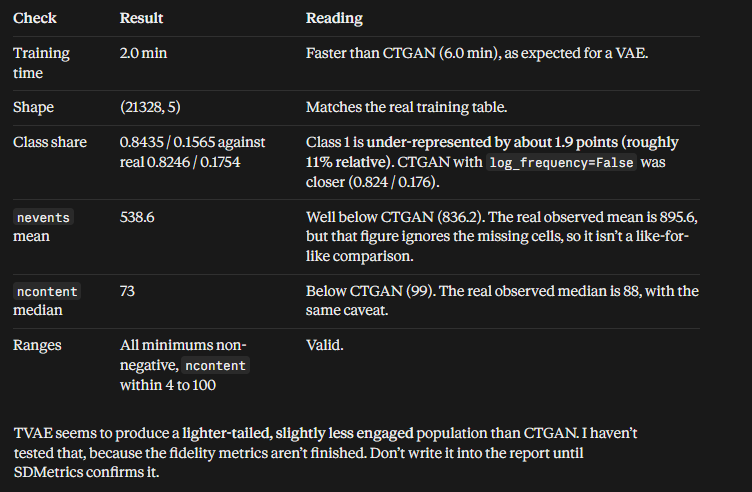

## Results: TVAE with target column (`random` table, unbalanced)

**Run:** 300 epochs, seed 42, SDV 2.0.0, `Engagement_Level` as a categorical generator column. Trained on `gen_input_random_target.csv` (real train only).

**Measured output**

| Check | Value |
|---|---|
| Training time | 2.0 min |
| Synthetic shape | 21,328 × 5 |
| Class share, real train (0 / 1) | 0.8246 / 0.1754 |
| Class share, synthetic (0 / 1) | 0.8435 / 0.1565 |
| `nevents` mean / median (synthetic) | 538.6 / 212 |
| `ncontent` median (synthetic) | 73 |

**Interpretation**
- The pipeline ran correctly, and the output is structurally valid (shape, integer types, non-negative values, `ncontent` within 4 to 100).
- Class 1 is under-represented by about 1.9 points. This is a modest distortion, but it is larger than CTGAN's with `log_frequency=False` (0.824 / 0.176).
- Summary statistics suggest a lighter-tailed distribution than CTGAN. This is a **hypothesis only**, to be tested with SDMetrics.
- These descriptive statistics are not a fidelity result. Real-column statistics ignore missing cells, so they are not like-for-like with the imputed generator inputs.



## Diagnostic: why is `Column Pair Trends` NaN?

**Purpose:** `evaluate_quality` returned `NaN` for Column Pair Trends, so the reported "overall quality" was identical to Column Shapes. That is not a valid overall score, and it must be fixed before any fidelity result is reported.

**Evidence so far:** per-pair details showed the real correlation was computed (0.14 to 0.31), but the synthetic correlation was `NaN` for all six pairs. The result stayed `NaN` when only complete rows were compared, so missing values alone do not explain it.

**Inputs (real train and generator output only; the test set is not used):**
- `train.csv` (real, with NaNs)
- `ctgan_random_restored.csv` (synthetic, NaNs restored)
- `gen_input_random.csv` and `ctgan_random.csv` (gap-free pair, used for Test 3 only)

**Tests (independent, so one failure does not hide the others):**
1. Plain pandas correlation, real train vs restored synthetic. This is ground truth for what the metric should compute.
2. `CorrelationSimilarity` called directly on one pair, so any error message is visible.
3. `evaluate_quality` on the gap-free pair. Diagnostic only. The official comparison stays real train (with NaNs) vs restored synthetic.



**Decision rule:**
- If Test 1 gives numbers but Test 2 fails, the SDMetrics call is the problem.
- If Test 3 works, the NaNs or the float dtype in the files trigger the failure.
- If everything fails, it is a version incompatibility (SDMetrics 0.32.0 with SDV 2.0.0), and pair trends will be computed manually and documented as a library limitation.

In [34]:
from pathlib import Path

import pandas as pd
from sdv.evaluation import evaluate_quality
from sdv.metadata import Metadata

FEATURES = ["nevents", "ndays_act", "ncontent", "nforum_posts"]
TABLE = "students"


def find_project_root(start=None):
    """Walk upwards until a folder containing configs/base.yaml is found."""
    start = Path(start or Path.cwd()).resolve()
    for folder in [start, *start.parents]:
        if (folder / "configs" / "base.yaml").exists():
            return folder
    raise FileNotFoundError(f"Could not find configs/base.yaml above {start}")


PROJECT_ROOT = find_project_root()
proc = PROJECT_ROOT / "data" / "processed"
gen = PROJECT_ROOT / "artifacts" / "generators"

real_train = pd.read_csv(proc / "train.csv")[FEATURES]
fake_restored = pd.read_csv(gen / "ctgan_random_restored.csv")[FEATURES]

# Test 1: plain pandas Pearson correlation (NaNs handled pairwise)
print("TEST 1: pandas correlation")
print(pd.DataFrame({
    "real_train": real_train.corr().stack(),
    "fake_restored": fake_restored.corr().stack(),
}).round(3).to_string())

# Test 2: the metric called directly on one pair
print("\nTEST 2: CorrelationSimilarity on (nevents, ndays_act)")
try:
    from sdmetrics.column_pairs import CorrelationSimilarity
    pair = ["nevents", "ndays_act"]
    score = CorrelationSimilarity.compute(
        real_train[pair].dropna(), fake_restored[pair].dropna()
    )
    print("score:", score)
except Exception as e:
    print("FAILED:", type(e).__name__, e)

# Test 3: gap-free comparison through evaluate_quality (diagnostic only)
print("\nTEST 3: imputed real vs unrestored fake (no NaNs, all integers)")
try:
    real_imp = pd.read_csv(proc / "gen_input_random.csv")[FEATURES]
    fake_raw = pd.read_csv(gen / "ctgan_random.csv")[FEATURES]
    md = Metadata.detect_from_dataframes({TABLE: real_imp})
    rep = evaluate_quality({TABLE: real_imp}, {TABLE: fake_raw}, md, verbose=False)
    print(rep.get_properties().to_string(index=False))
    print(rep.get_details("Column Pair Trends").iloc[:, [1, 2, 4, 5, 6]].to_string(index=False))
except Exception as e:
    print("FAILED:", type(e).__name__, e)

TEST 1: pandas correlation
                           real_train  fake_restored
nevents      nevents            1.000          1.000
             ndays_act          0.264          0.342
             ncontent           0.197          0.300
             nforum_posts       0.176          0.407
ndays_act    nevents            0.264          0.342
             ndays_act          1.000          1.000
             ncontent           0.273          0.358
             nforum_posts       0.311          0.352
ncontent     nevents            0.197          0.300
             ndays_act          0.273          0.358
             ncontent           1.000          1.000
             nforum_posts       0.141          0.329
nforum_posts nevents            0.176          0.407
             ndays_act          0.311          0.352
             ncontent           0.141          0.329
             nforum_posts       1.000          1.000

TEST 2: CorrelationSimilarity on (nevents, ndays_act)
score: 0.96109362

## Results: diagnosis of the NaN pair-trends score

**Finding:** `evaluate_quality` (SDV 2.0.0, SDMetrics 0.32.0) returns `NaN` for Column Pair Trends even on gap-free integer data. Calling `CorrelationSimilarity` directly works (nevents–ndays_act: 0.961). The fault is therefore in the report's pair-trends step in this version combination, not in the data.

**Decision:** compute pair trends manually as the mean of `CorrelationSimilarity` over the six feature pairs, and compute overall quality as the mean of Column Shapes and Column Pair Trends. Document this as a library limitation.

**Observation (hypothesis only):** pandas correlations of the synthetic data are consistently higher than the real data's (e.g. nevents–nforum_posts: 0.407 vs 0.176). A possible cause is KNN imputation tightening relationships before generator training. Not yet tested.



## Synthetic fidelity (corrected): CTGAN and TVAE, `random` strategy, no-target baseline

**Purpose:** replace the invalid quality scores from the first evaluation (Column Pair Trends was `NaN`, so "overall quality" equalled Column Shapes).

**Comparison:** real `train.csv` (with genuine NaNs) vs the restored synthetic files `ctgan_random_restored.csv` and `tvae_random_restored.csv`. **Fidelity is measured against train only. The test set is never used.**

**Metrics:**
- **Column Shapes:** from SDV's report (works correctly).
- **Column Pair Trends:** mean of `CorrelationSimilarity` across the six feature pairs, computed directly. Each pair uses rows where both values are present.
- **Overall quality:** mean of the two scores above.
- **Missing-value similarity:** `MissingValueSimilarity` per column.

**Known limitation:** the manual pair-trends score replaces SDV's report because of the `NaN` fault. It follows the same idea but is not guaranteed identical to SDV's own calculation, so values should not be compared to the paper's to the last decimal.

**Output:** `reports/synthetic_quality_random_baseline.json`. The earlier `synthetic_quality_random.json` held invalid values and is deleted by this cell.



In [35]:
import json
from itertools import combinations
from pathlib import Path

import pandas as pd
import sdmetrics
import sdv
from sdmetrics.column_pairs import CorrelationSimilarity
from sdmetrics.single_column import MissingValueSimilarity
from sdv.evaluation import evaluate_quality
from sdv.metadata import Metadata

FEATURES = ["nevents", "ndays_act", "ncontent", "nforum_posts"]
TABLE = "students"


def find_project_root(start=None):
    """Walk upwards until a folder containing configs/base.yaml is found."""
    start = Path(start or Path.cwd()).resolve()
    for folder in [start, *start.parents]:
        if (folder / "configs" / "base.yaml").exists():
            return folder
    raise FileNotFoundError(f"Could not find configs/base.yaml above {start}")


def pair_trends(real: pd.DataFrame, fake: pd.DataFrame) -> tuple[float, dict]:
    """Mean CorrelationSimilarity over all feature pairs (pairwise-complete rows)."""
    scores = {}
    for a, b in combinations(FEATURES, 2):
        pair = [a, b]
        scores[f"{a}|{b}"] = float(
            CorrelationSimilarity.compute(real[pair].dropna(), fake[pair].dropna())
        )
    return sum(scores.values()) / len(scores), scores


def column_shapes(real: pd.DataFrame, fake: pd.DataFrame, metadata) -> float:
    """Column Shapes score from the SDV quality report."""
    report = evaluate_quality({TABLE: real}, {TABLE: fake}, metadata, verbose=False)
    props = report.get_properties()
    return float(props.loc[props["Property"] == "Column Shapes", "Score"].iloc[0])


PROJECT_ROOT = find_project_root()
gen_dir = PROJECT_ROOT / "artifacts" / "generators"
report_dir = PROJECT_ROOT / "reports"
report_dir.mkdir(exist_ok=True)

real_train = pd.read_csv(PROJECT_ROOT / "data" / "processed" / "train.csv")[FEATURES]
metadata = Metadata.detect_from_dataframes({TABLE: real_train})

results = {
    "sdv": sdv.__version__, "sdmetrics": sdmetrics.__version__,
    "strategy": "random", "variant": "no-target baseline",
    "compared_against": "real train (with NaNs)",
    "note": "pair trends computed manually: SDV report returned NaN",
    "generators": {},
}

for name in ("ctgan", "tvae"):
    fake = pd.read_csv(gen_dir / f"{name}_random_restored.csv")[FEATURES]

    shapes = column_shapes(real_train, fake, metadata)
    trends, per_pair = pair_trends(real_train, fake)
    missing = {c: float(MissingValueSimilarity.compute(real_train[c], fake[c])) for c in FEATURES}

    results["generators"][name] = {
        "column_shapes": shapes,
        "pair_trends": trends,
        "overall_quality": (shapes + trends) / 2,
        "pair_trends_per_pair": per_pair,
        "missing_value_similarity": missing,
    }

    print(f"=== {name.upper()} ===")
    print(f"Column Shapes : {shapes:.4f}")
    print(f"Pair Trends   : {trends:.4f}")
    print(f"Overall       : {(shapes + trends) / 2:.4f}")
    print("Per pair      :", {k: round(v, 3) for k, v in per_pair.items()})
    print("Missing sim.  :", {k: round(v, 4) for k, v in missing.items()})
    print()

old = report_dir / "synthetic_quality_random.json"
if old.exists():
    old.unlink()

out_path = report_dir / "synthetic_quality_random_baseline.json"
with open(out_path, "w", encoding="utf-8") as f:
    json.dump(results, f, indent=2)
print("Saved:", out_path)

=== CTGAN ===
Column Shapes : 0.8942
Pair Trends   : 0.9394
Overall       : 0.9168
Per pair      : {'nevents|ndays_act': 0.961, 'nevents|ncontent': 0.949, 'nevents|nforum_posts': 0.884, 'ndays_act|ncontent': 0.957, 'ndays_act|nforum_posts': 0.979, 'ncontent|nforum_posts': 0.906}
Missing sim.  : {'nevents': 0.9996, 'ndays_act': 0.9995, 'ncontent': 1.0, 'nforum_posts': 0.9962}

=== TVAE ===
Column Shapes : 0.8643
Pair Trends   : 0.9338
Overall       : 0.8990
Per pair      : {'nevents|ndays_act': 0.964, 'nevents|ncontent': 0.893, 'nevents|nforum_posts': 0.899, 'ndays_act|ncontent': 0.955, 'ndays_act|nforum_posts': 0.898, 'ncontent|nforum_posts': 0.993}
Missing sim.  : {'nevents': 0.9996, 'ndays_act': 0.9995, 'ncontent': 1.0, 'nforum_posts': 0.9962}

Saved: D:\student_engagement_twin\reports\synthetic_quality_random_baseline.json


 synthetic fidelity, `random` strategy, no-target baseline

**Setup:** CTGAN and TVAE (300 epochs, seed 42, SDV 2.0.0, SDMetrics 0.32.0) trained on 4 imputed features without the target. NaNs restored at training missing rates. Compared against **real train with NaNs** (never the test set). Saved in `reports/synthetic_quality_random_baseline.json`.

**Measured**

| Metric | CTGAN | TVAE |
|---|---|---|
| Column Shapes | 0.8942 | 0.8643 |
| Column Pair Trends (manual) | 0.9394 | 0.9338 |
| Overall quality (mean of the two) | 0.9168 | 0.8990 |
| Missing-value similarity (nevents / ndays_act / ncontent / nforum_posts) | 0.9996 / 0.9995 / 1.0 / 0.9962 | identical |

**Interpretation**
- CTGAN scores slightly higher than TVAE on both metrics. The gap is small and comes from one seed, so no winner is claimed.
- Missing-value similarity is identical for both generators because the NaNs were restored by the same seeded procedure. It validates the restoration step, not the generators.
- Weakest pairs: CTGAN `nevents|nforum_posts` (0.884) and TVAE `nevents|ncontent` (0.893).

**Comparison with the paper (reference only):** paper overall quality for random missingness is CTGAN 83.55%, TVAE 89.92%. Ours are 91.68% and 89.90%. The ordering differs. These are not directly comparable: the pair-trends score is computed manually, and this is a no-target baseline.

**Limitation:** `evaluate_quality` returned `NaN` for pair trends in this version combination, so pair trends were computed directly with `CorrelationSimilarity`.

## Restore NaNs (`random` strategy) for the target-variant generators

**Purpose:** the generators trained with `Engagement_Level` produced gap-free synthetic rows. Missing values must be put back before measuring fidelity or training XGBoost, since the real test data has genuine NaNs.

**Inputs:**
- `ctgan_random_target.csv` and `tvae_random_target.csv` (synthetic, 4 features + label)
- `train.csv`, **used only to learn per-column missing rates** (test set not used)

**Method:** the same `random` strategy as the baseline. For each of the four features, hide cells at random at the real training missing rate, with a fixed seed.

**Decision:** `Engagement_Level` is **never** masked. It is the label, and a missing label would make the row unusable.

**Checks printed:**
1. Restored missing rates against real train rates.
2. Label column has zero NaNs and the same class share as before restoration.
3. `ncontent` stays at exactly 0% missing.

**Outputs:** `ctgan_random_target_restored.csv` and `tvae_random_target_restored.csv` in `artifacts/generators/`.

**Expected result:** rates within about 0.5 points of real (17.08 / 10.53 / 0 / 68.11), label untouched.

In [36]:
from pathlib import Path

import numpy as np
import pandas as pd

FEATURES = ["nevents", "ndays_act", "ncontent", "nforum_posts"]
TARGET = "Engagement_Level"
SEED = 42


def find_project_root(start=None):
    """Walk upwards until a folder containing configs/base.yaml is found."""
    start = Path(start or Path.cwd()).resolve()
    for folder in [start, *start.parents]:
        if (folder / "configs" / "base.yaml").exists():
            return folder
    raise FileNotFoundError(f"Could not find configs/base.yaml above {start}")


def restore_random(df: pd.DataFrame, miss_rates: pd.Series, seed: int) -> pd.DataFrame:
    """Hide feature cells at the learned rates. The target column is left untouched."""
    rng = np.random.default_rng(seed)
    out = df[FEATURES + [TARGET]].copy()
    out[FEATURES] = out[FEATURES].astype(float)
    for col in FEATURES:
        out.loc[rng.random(len(out)) < miss_rates[col], col] = np.nan
    return out


PROJECT_ROOT = find_project_root()
gen_dir = PROJECT_ROOT / "artifacts" / "generators"

real_train = pd.read_csv(PROJECT_ROOT / "data" / "processed" / "train.csv")
miss_rates = real_train[FEATURES].isna().mean()

rows = {"real": real_train[FEATURES].isna().mean() * 100}
for name in ("ctgan", "tvae"):
    fake = pd.read_csv(gen_dir / f"{name}_random_target.csv")
    restored = restore_random(fake, miss_rates, SEED)
    restored.to_csv(gen_dir / f"{name}_random_target_restored.csv", index=False)

    rows[name] = restored[FEATURES].isna().mean() * 100
    assert restored[TARGET].isna().sum() == 0, "label must never be masked"
    assert restored[TARGET].equals(fake[TARGET]), "label values changed"
    print(f"{name}: label NaNs = 0, class share = "
          f"{restored[TARGET].value_counts(normalize=True).round(4).to_dict()}")

print("\nMissing % per column")
print(pd.DataFrame(rows).round(2))

ctgan: label NaNs = 0, class share = {0: 0.824, 1: 0.176}
tvae: label NaNs = 0, class share = {0: 0.8435, 1: 0.1565}

Missing % per column
               real  ctgan   tvae
nevents       17.08  17.12  17.12
ndays_act     10.53  10.48  10.48
ncontent       0.00   0.00   0.00
nforum_posts  68.11  68.48  68.48


## Results: NaN restoration for the target-variant generators (`random` strategy)

**Setup:** `ctgan_random_target.csv` and `tvae_random_target.csv` (300 epochs, seed 42, `Engagement_Level` as a categorical generator column). Missing rates were learned from real train only and applied to the four feature columns. The label column was never masked.

**Measured**

| Column | Real train | Restored (both generators) |
|---|---|---|
| nevents | 17.08% | 17.12% |
| ndays_act | 10.53% | 10.48% |
| ncontent | 0.00% | 0.00% |
| nforum_posts | 68.11% | 68.48% |

Class share after restoration: CTGAN 0.824 / 0.176, TVAE 0.8435 / 0.1565 (unchanged from before restoration). Label NaNs: 0 for both.

**Interpretation**
- Restoration reproduces the per-column missing proportions within 0.4 points.
- Both generators have identical masks, because the same seed and rates were used. Missingness is independent of feature values and label by construction.

**Limitation:** the `random` strategy recreates proportions, not the real relationship between missingness and behaviour, such as forum silence and low completion. The `from_column` strategy is the one that can model this, and it is not built yet.

**Outputs:** `ctgan_random_target_restored.csv`, `tvae_random_target_restored.csv`.

## Synthetic fidelity: CTGAN and TVAE with target column (`random` strategy)

**Purpose:** measure how closely the target-variant synthetic data matches real training data. This is the paper's main experimental setting.

**Comparison:** real `train.csv` (features + `Engagement_Level`, genuine NaNs) vs `*_random_target_restored.csv`. **Fidelity is measured against train only. The test set is never used.**

**Metrics:**
- **Column Shapes:** SDV report, over five columns. `Engagement_Level` is declared categorical, so its class distribution is scored too.
- **Column Pair Trends:** mean `CorrelationSimilarity` over the six feature pairs, computed directly (the SDV report returns `NaN` for this property in SDV 2.0.0 / SDMetrics 0.32.0). It covers the four numeric features only, because correlation is not defined for the categorical label.
- **Overall quality:** mean of the two scores above.
- **Missing-value similarity:** per feature column.
- **Class share:** real vs synthetic.

**Comparability note:** Column Shapes here averages five columns and the baseline averaged four, so the two columns are not strictly like-for-like. The comparison table is indicative only.




In [37]:
import json
from itertools import combinations
from pathlib import Path

import pandas as pd
import sdmetrics
import sdv
from sdmetrics.column_pairs import CorrelationSimilarity
from sdmetrics.single_column import MissingValueSimilarity
from sdv.evaluation import evaluate_quality
from sdv.metadata import Metadata

FEATURES = ["nevents", "ndays_act", "ncontent", "nforum_posts"]
TARGET = "Engagement_Level"
TABLE = "students"


def find_project_root(start=None):
    """Walk upwards until a folder containing configs/base.yaml is found."""
    start = Path(start or Path.cwd()).resolve()
    for folder in [start, *start.parents]:
        if (folder / "configs" / "base.yaml").exists():
            return folder
    raise FileNotFoundError(f"Could not find configs/base.yaml above {start}")


def build_metadata(df: pd.DataFrame) -> Metadata:
    """Detect metadata and mark the label as categorical."""
    metadata = Metadata.detect_from_dataframes({TABLE: df})
    metadata.update_column(column_name=TARGET, table_name=TABLE, sdtype="categorical")
    return metadata


def pair_trends(real: pd.DataFrame, fake: pd.DataFrame) -> tuple[float, dict]:
    """Mean CorrelationSimilarity over all feature pairs (pairwise-complete rows)."""
    scores = {}
    for a, b in combinations(FEATURES, 2):
        pair = [a, b]
        scores[f"{a}|{b}"] = float(
            CorrelationSimilarity.compute(real[pair].dropna(), fake[pair].dropna())
        )
    return sum(scores.values()) / len(scores), scores


def column_shapes(real: pd.DataFrame, fake: pd.DataFrame, metadata) -> float:
    """Column Shapes score from the SDV quality report."""
    report = evaluate_quality({TABLE: real}, {TABLE: fake}, metadata, verbose=False)
    props = report.get_properties()
    return float(props.loc[props["Property"] == "Column Shapes", "Score"].iloc[0])


PROJECT_ROOT = find_project_root()
gen_dir = PROJECT_ROOT / "artifacts" / "generators"
report_dir = PROJECT_ROOT / "reports"

real_train = pd.read_csv(PROJECT_ROOT / "data" / "processed" / "train.csv")[FEATURES + [TARGET]]
metadata = build_metadata(real_train)

results = {
    "sdv": sdv.__version__, "sdmetrics": sdmetrics.__version__,
    "strategy": "random", "variant": "target as generator column (unbalanced)",
    "compared_against": "real train (with NaNs)",
    "note": "pair trends computed manually over the 4 features: SDV report returned NaN",
    "generators": {},
}

for name in ("ctgan", "tvae"):
    fake = pd.read_csv(gen_dir / f"{name}_random_target_restored.csv")[FEATURES + [TARGET]]

    shapes = column_shapes(real_train, fake, metadata)
    trends, per_pair = pair_trends(real_train, fake)
    missing = {c: float(MissingValueSimilarity.compute(real_train[c], fake[c])) for c in FEATURES}
    share = fake[TARGET].value_counts(normalize=True).round(4).to_dict()

    results["generators"][name] = {
        "column_shapes": shapes,
        "pair_trends": trends,
        "overall_quality": (shapes + trends) / 2,
        "pair_trends_per_pair": per_pair,
        "missing_value_similarity": missing,
        "class_share_synthetic": {str(k): v for k, v in share.items()},
    }

    print(f"=== {name.upper()} (with target) ===")
    print(f"Column Shapes : {shapes:.4f}")
    print(f"Pair Trends   : {trends:.4f}")
    print(f"Overall       : {(shapes + trends) / 2:.4f}")
    print("Per pair      :", {k: round(v, 3) for k, v in per_pair.items()})
    print("Missing sim.  :", {k: round(v, 4) for k, v in missing.items()})
    print("Class share   :", share)
    print()

out_path = report_dir / "synthetic_quality_random_target.json"
with open(out_path, "w", encoding="utf-8") as f:
    json.dump(results, f, indent=2)
print("Saved:", out_path)

# Indicative comparison with the no-target baseline
base_path = report_dir / "synthetic_quality_random_baseline.json"
if base_path.exists():
    base = json.loads(base_path.read_text(encoding="utf-8"))["generators"]
    table = pd.DataFrame({
        f"{n}_{variant}": {
            "shapes": g[n]["column_shapes"],
            "pairs": g[n]["pair_trends"],
            "overall": g[n]["overall_quality"],
        }
        for n in ("ctgan", "tvae")
        for variant, g in (("baseline", base), ("target", results["generators"]))
    }).round(4)
    print("\nBaseline vs target variant (indicative only):")
    print(table)

=== CTGAN (with target) ===
Column Shapes : 0.9343
Pair Trends   : 0.9624
Overall       : 0.9483
Per pair      : {'nevents|ndays_act': 0.993, 'nevents|ncontent': 0.978, 'nevents|nforum_posts': 0.918, 'ndays_act|ncontent': 0.984, 'ndays_act|nforum_posts': 0.988, 'ncontent|nforum_posts': 0.913}
Missing sim.  : {'nevents': 0.9996, 'ndays_act': 0.9995, 'ncontent': 1.0, 'nforum_posts': 0.9962}
Class share   : {0: 0.824, 1: 0.176}

=== TVAE (with target) ===
Column Shapes : 0.9141
Pair Trends   : 0.9273
Overall       : 0.9207
Per pair      : {'nevents|ndays_act': 0.97, 'nevents|ncontent': 0.888, 'nevents|nforum_posts': 0.83, 'ndays_act|ncontent': 0.998, 'ndays_act|nforum_posts': 0.968, 'ncontent|nforum_posts': 0.909}
Missing sim.  : {'nevents': 0.9996, 'ndays_act': 0.9995, 'ncontent': 1.0, 'nforum_posts': 0.9962}
Class share   : {0: 0.8435, 1: 0.1565}

Saved: D:\student_engagement_twin\reports\synthetic_quality_random_target.json

Baseline vs target variant (indicative only):
         ctgan_

## Results: synthetic fidelity, `random` strategy, target as generator column (unbalanced)

**Setup:** CTGAN (`log_frequency=False`) and TVAE, 300 epochs, seed 42, SDV 2.0.0, SDMetrics 0.32.0. `Engagement_Level` is a categorical generator column. NaNs restored at training missing rates. Compared against **real train with NaNs** (never the test set). Saved in `reports/synthetic_quality_random_target.json`.

**Measured**

| Metric | CTGAN | TVAE |
|---|---|---|
| Column Shapes (5 columns incl. label) | 0.9343 | 0.9141 |
| Column Pair Trends (manual, 4 features) | 0.9624 | 0.9273 |
| Overall quality | 0.9483 | 0.9207 |
| Class share, synthetic (0 / 1) | 0.824 / 0.176 | 0.8435 / 0.1565 |

Real train class share: 0.8246 / 0.1754.

**Interpretation**
- CTGAN scores higher than TVAE on both metrics. This is one seed, so no winner is claimed.
- CTGAN preserves the real class share. TVAE under-represents class 1 by about 1.9 points.
- Weakest pairs all involve `nforum_posts` (TVAE `nevents|nforum_posts` 0.830).
- **Baseline comparison is indicative only.** Column Shapes now averages five columns, and the label column scores near 1, which lifts the average mechanically. Pair Trends is like-for-like and moved in opposite directions (CTGAN +0.023, TVAE -0.007), so no consistent effect of adding the label can be claimed from one seed.

**Comparison with the paper (reference only):** paper overall quality for random missingness is CTGAN 83.55%, TVAE 89.92%. Ours are 94.83% and 92.07%. Ranking differs, and the pair-trends calculation is not identical, so these are not directly comparable.

**Limitation:** a single seed per generator, so run-to-run variance is unknown.

## Predictive utility: XGBoost trained on synthetic data, evaluated on real test data

**Purpose:** measure whether a classifier trained only on synthetic student records predicts engagement on real, unseen students. This is Objective 4 of the project proposal.

**Experiments (all unbalanced, `random` strategy):**
1. `ctgan_random_target`: trained on `ctgan_random_target_restored.csv`
2. `tvae_random_target`: trained on `tvae_random_target_restored.csv`
3. `real_train_reference`: trained on real `train.csv`. This is a **reference ceiling**, not part of the paper's method.

**Inputs:**
- Classifier features: only the four activity features, in the fixed order `nevents, ndays_act, ncontent, nforum_posts`. `Engagement_Level` is used only as the training label. `completed_%` does not exist in any of these files.
- Synthetic training rows keep their NaNs. XGBoost handles them natively.
- Evaluation: real `test.csv` (5,333 rows) with its genuine NaNs and original class share.

**Leakage controls:**
- The test set is used **only** for the final metrics. No hyperparameter, threshold or model selection is done on it.
- XGBoost parameters are fixed in advance and identical for all three runs (`n_estimators=200, max_depth=4, learning_rate=0.1`). They are not tuned, and will move into `base.yaml` during refactoring.

**Metrics:**
- Weighted precision, recall and F1, which is what the paper reports.
- Per-class precision, recall and F1, and the confusion matrix.
- Weighted scores are dominated by the majority class (about 82.5% of rows). The **class-1 metrics** are the more informative figures for the minority class and must be read alongside them.



In [38]:
import json
from datetime import datetime, timezone
from pathlib import Path

import joblib
import pandas as pd
import sklearn
import xgboost
from sklearn.metrics import classification_report, confusion_matrix, precision_recall_fscore_support
from xgboost import XGBClassifier

FEATURES = ["nevents", "ndays_act", "ncontent", "nforum_posts"]
TARGET = "Engagement_Level"
SEED = 42
XGB_PARAMS = dict(
    n_estimators=200, max_depth=4, learning_rate=0.1,
    random_state=SEED, eval_metric="logloss",
)


def find_project_root(start=None):
    """Walk upwards until a folder containing configs/base.yaml is found."""
    start = Path(start or Path.cwd()).resolve()
    for folder in [start, *start.parents]:
        if (folder / "configs" / "base.yaml").exists():
            return folder
    raise FileNotFoundError(f"Could not find configs/base.yaml above {start}")


def check_columns(df: pd.DataFrame, label: str) -> pd.DataFrame:
    """Return df restricted to features + target, in the fixed order."""
    expected = FEATURES + [TARGET]
    missing = [c for c in expected if c not in df.columns]
    if missing:
        raise ValueError(f"{label}: missing columns {missing}")
    return df[expected]


def evaluate(model: XGBClassifier, test: pd.DataFrame) -> dict:
    """Weighted and per-class metrics on the real test set."""
    y_true = test[TARGET].astype(int)
    y_pred = model.predict(test[FEATURES])
    p, r, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average="weighted", zero_division=0
    )
    per_class = classification_report(y_true, y_pred, output_dict=True, zero_division=0)
    return {
        "weighted": {"precision": float(p), "recall": float(r), "f1": float(f1)},
        "per_class": {k: per_class[k] for k in ("0", "1")},
        "confusion_matrix": confusion_matrix(y_true, y_pred).tolist(),
        "test_class_counts": {str(k): int(v) for k, v in y_true.value_counts().sort_index().items()},
    }


def run_experiment(name: str, train_df: pd.DataFrame, test: pd.DataFrame, model_dir: Path) -> dict:
    """Train on train_df (features + label) and evaluate on the real test set."""
    train_df = check_columns(train_df, name)
    model = XGBClassifier(**XGB_PARAMS)
    model.fit(train_df[FEATURES], train_df[TARGET].astype(int))
    joblib.dump(model, model_dir / f"{name}.joblib")

    result = evaluate(model, test)
    result["train_rows"] = len(train_df)
    result["train_class_share"] = {
        str(k): round(float(v), 4)
        for k, v in train_df[TARGET].value_counts(normalize=True).sort_index().items()
    }
    result["train_feature_nan_pct"] = (train_df[FEATURES].isna().mean() * 100).round(2).to_dict()
    return result


PROJECT_ROOT = find_project_root()
proc = PROJECT_ROOT / "data" / "processed"
gen_dir = PROJECT_ROOT / "artifacts" / "generators"
model_dir = PROJECT_ROOT / "artifacts" / "models"
model_dir.mkdir(parents=True, exist_ok=True)
report_dir = PROJECT_ROOT / "reports"

# The real test set: loaded for final evaluation only
test = check_columns(pd.read_csv(proc / "test.csv"), "test")
print("Test:", test.shape, "| NaN % per feature:", (test[FEATURES].isna().mean() * 100).round(2).to_dict())
print("Test class share:", test[TARGET].value_counts(normalize=True).round(4).to_dict())

experiments = {
    "real_train_reference": pd.read_csv(proc / "train.csv"),
    "ctgan_random_target": pd.read_csv(gen_dir / "ctgan_random_target_restored.csv"),
    "tvae_random_target": pd.read_csv(gen_dir / "tvae_random_target_restored.csv"),
}

results = {}
for name, df in experiments.items():
    results[name] = run_experiment(name, df, test, model_dir)

summary = pd.DataFrame({
    name: {
        "w_precision": r["weighted"]["precision"],
        "w_recall": r["weighted"]["recall"],
        "w_f1": r["weighted"]["f1"],
        "class1_precision": r["per_class"]["1"]["precision"],
        "class1_recall": r["per_class"]["1"]["recall"],
        "class1_f1": r["per_class"]["1"]["f1-score"],
    }
    for name, r in results.items()
}).round(4)
print("\n", summary)
for name, r in results.items():
    print(f"\nConfusion matrix, {name} (rows = true 0/1, cols = predicted 0/1):")
    print(r["confusion_matrix"])

payload = {
    "timestamp_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "seed": SEED,
    "xgb_params": XGB_PARAMS,
    "features": FEATURES,
    "target": TARGET,
    "strategy": "random",
    "variant": "target as generator column (unbalanced)",
    "evaluated_on": "real test set (final evaluation only; no tuning)",
    "versions": {"xgboost": xgboost.__version__, "sklearn": sklearn.__version__, "pandas": pd.__version__},
    "experiments": results,
}
out = report_dir / "xgb_random_target.json"
out.write_text(json.dumps(payload, indent=2), encoding="utf-8")
print("\nSaved:", out)

Test: (5333, 5) | NaN % per feature: {'nevents': 17.1, 'ndays_act': 10.09, 'ncontent': 0.0, 'nforum_posts': 67.84}
Test class share: {0: 0.8247, 1: 0.1753}

                   real_train_reference  ctgan_random_target  \
w_precision                     0.9055               0.8665   
w_recall                        0.9087               0.8766   
w_f1                            0.9065               0.8669   
class1_precision                0.7692               0.7174   
class1_recall                   0.6845               0.4888   
class1_f1                       0.7244               0.5814   

                  tvae_random_target  
w_precision                   0.8944  
w_recall                      0.8995  
w_f1                          0.8956  
class1_precision              0.7588  
class1_recall                 0.6257  
class1_f1                     0.6858  

Confusion matrix, real_train_reference (rows = true 0/1, cols = predicted 0/1):
[[4206, 192], [295, 640]]

Confusion matrix, c

## Results: XGBoost trained on synthetic data, evaluated on real test data (`random`, unbalanced)

**Setup:** XGBoost (`n_estimators=200, max_depth=4, learning_rate=0.1`, seed 42, fixed in advance, not tuned) trained on three sources and evaluated on the real test set (5,333 rows: 4,398 class 0, 935 class 1). The test set was used only for these final metrics. Features: `nevents, ndays_act, ncontent, nforum_posts` only. Saved in `reports/xgb_random_target.json`; models in `artifacts/models/`.

**Measured**

| Metric | Real-train reference | CTGAN (synthetic) | TVAE (synthetic) |
|---|---|---|---|
| Weighted precision | 0.9055 | 0.8665 | 0.8944 |
| Weighted recall | 0.9087 | 0.8766 | 0.8995 |
| Weighted F1 | 0.9065 | 0.8669 | 0.8956 |
| Class-1 precision | 0.7692 | 0.7174 | 0.7588 |
| Class-1 recall | 0.6845 | 0.4888 | 0.6257 |
| Class-1 F1 | 0.7244 | 0.5814 | 0.6858 |
| Confusion matrix [[TN, FP], [FN, TP]] | [[4206, 192], [295, 640]] | [[4218, 180], [478, 457]] | [[4212, 186], [350, 585]] |

**Interpretation**
- Weighted scores are dominated by class 0. Class-1 metrics are the informative ones.
- False positives are nearly equal across models. The difference is in false negatives: CTGAN misses 51% of high-engagement students, TVAE 37%, the real-data reference 32%.
- TVAE is closest to the real-data reference. The fidelity ranking (CTGAN above TVAE) does not carry over to predictive utility. This is a single-seed observation.
- The reference model (real train, test class-1 recall 0.685) is consistent with the labeler's cross-validated recall on train (0.672), so no leakage is indicated.

**Comparison with the paper (reference only):** paper unbalanced F1 for random missingness is CTGAN 85%, TVAE 90%. Ours are 86.7% and 89.6%. Same ordering, not a replication claim.

**Hypothesis (untested):** `random` masking is independent of the label, so synthetic data lacks the real relationship between missing `nforum_posts` and engagement.

**Limitations:** one seed, no confidence intervals, fixed untuned XGBoost parameters.

## Diagnostic: conditional sampling for class balancing (SDV 2.0)

**Purpose:** the paper balances engagement classes by conditionally sampling CTGAN and TVAE. Before building the balanced experiment, find out how SDV 2.0.0 exposes this, instead of assuming the 1.x interface.

**Inputs:** the saved generators `ctgan_random_target.pkl` and `tvae_random_target.pkl` (trained on real train only). No real data is loaded and the test set is not touched.

**Checks (independent, so one failure does not hide the other):**
1. Which names exist in `sdv.sampling`, and which sampling methods each synthesizer has.
2. The signature of `sample_from_conditions`.
3. A **trial run**: load each generator and request 100 rows of class 1, then 100 rows of class 0. The class counts of the result are printed.


**Decision rule:**
- If the trial returns 100 rows of the requested class, the balanced experiment can use this method directly.
- If a generator fails or returns the wrong class, the printed error shows how SDV 2.0 differs, and the balanced-sampling cell will be written around it.
- Any failure is documented as a library limitation and is not worked around silently.

In [39]:
import inspect
from pathlib import Path

import pandas as pd
import sdv
import sdv.sampling as smp
from sdv.single_table import CTGANSynthesizer, TVAESynthesizer

TARGET = "Engagement_Level"
TABLE = "students"
N_TRIAL = 100


def find_project_root(start=None):
    """Walk upwards until a folder containing configs/base.yaml is found."""
    start = Path(start or Path.cwd()).resolve()
    for folder in [start, *start.parents]:
        if (folder / "configs" / "base.yaml").exists():
            return folder
    raise FileNotFoundError(f"Could not find configs/base.yaml above {start}")


def unwrap(result):
    """Return a DataFrame whether SDV gave us a DataFrame or {table: DataFrame}."""
    if isinstance(result, dict):
        return result[TABLE] if TABLE in result else next(iter(result.values()))
    return result


PROJECT_ROOT = find_project_root()
gen_dir = PROJECT_ROOT / "artifacts" / "generators"

print("sdv:", sdv.__version__)
print("Names in sdv.sampling:", [n for n in dir(smp) if not n.startswith("_")])

for cls in (CTGANSynthesizer, TVAESynthesizer):
    methods = [m for m in dir(cls) if "sample" in m and not m.startswith("_")]
    print(f"\n{cls.__name__} sampling methods: {methods}")
    if hasattr(cls, "sample_from_conditions"):
        print("sample_from_conditions signature:", inspect.signature(cls.sample_from_conditions))

print("\n--- Trial: 100 rows per class ---")
for name, cls in (("ctgan", CTGANSynthesizer), ("tvae", TVAESynthesizer)):
    try:
        from sdv.sampling import Condition
        synth = cls.load(str(gen_dir / f"{name}_random_target.pkl"))
        for label in (1, 0):
            cond = Condition(column_values={TARGET: label}, num_rows=N_TRIAL)
            out = unwrap(synth.sample_from_conditions(conditions=[cond]))
            print(f"{name} | requested class {label}: shape={out.shape}, "
                  f"classes returned={out[TARGET].value_counts().to_dict()}")
    except Exception as e:
        print(f"{name} | FAILED: {type(e).__name__}: {e}")

sdv: 2.0.0
Names in sdv.sampling: ['BaseHierarchicalSampler', 'BaseIndependentSampler', 'Condition', 'DataFrameCondition', 'MultiTableCondition', 'hierarchical_sampler', 'independent_sampler', 'tabular']

CTGANSynthesizer sampling methods: ['sample', 'sample_from_conditions', 'sample_remaining_columns']
sample_from_conditions signature: (self, conditions, max_tries_per_batch=100, batch_size=None, output_folder_path=None)

TVAESynthesizer sampling methods: ['sample', 'sample_from_conditions', 'sample_remaining_columns']
sample_from_conditions signature: (self, conditions, max_tries_per_batch=100, batch_size=None, output_folder_path=None)

--- Trial: 100 rows per class ---
ctgan | FAILED: AttributeError: type object 'CTGANSynthesizer' has no attribute 'load'
tvae | FAILED: AttributeError: type object 'TVAESynthesizer' has no attribute 'load'


## Results: SDV 2.0.0 conditional-sampling API check

**Finding 1:** `sample_from_conditions(conditions, max_tries_per_batch=100, batch_size=None, output_folder_path=None)` exists on both `CTGANSynthesizer` and `TVAESynthesizer`. `sdv.sampling` provides `Condition`, `DataFrameCondition` and `MultiTableCondition`.

**Finding 2:** `CTGANSynthesizer.load` and `TVAESynthesizer.load` do not exist in SDV 2.0.0, so saved synthesizers cannot be reloaded with the 1.x call. Trial sampling was therefore **not executed**, and no claim is made yet about whether conditional sampling returns the requested class.

**Library note (for the README):** SDV 2.0.0 removed the class-level `.load()` that SDV 1.x provided.



In [40]:
import inspect
from pathlib import Path

import sdv
import sdv.utils as sutils
from sdv.sampling import Condition, DataFrameCondition
from sdv.single_table import CTGANSynthesizer


def find_project_root(start=None):
    """Walk upwards until a folder containing configs/base.yaml is found."""
    start = Path(start or Path.cwd()).resolve()
    for folder in [start, *start.parents]:
        if (folder / "configs" / "base.yaml").exists():
            return folder
    raise FileNotFoundError(f"Could not find configs/base.yaml above {start}")


PROJECT_ROOT = find_project_root()
path = str(PROJECT_ROOT / "artifacts" / "generators" / "ctgan_random_target.pkl")

print("sdv:", sdv.__version__)
print("sdv.utils names with load/save:",
      [n for n in dir(sutils) if "load" in n.lower() or "save" in n.lower()])
print("CTGANSynthesizer names with load/save:",
      [n for n in dir(CTGANSynthesizer) if "load" in n.lower() or "save" in n.lower()])

print("\nCondition signature         :", inspect.signature(Condition.__init__))
print("DataFrameCondition signature:", inspect.signature(DataFrameCondition.__init__))

print("\n--- Loader candidates on the saved CTGAN file ---")
candidates = []
if hasattr(sutils, "load_synthesizer"):
    candidates.append(("sdv.utils.load_synthesizer", lambda: sutils.load_synthesizer(path)))
try:
    from sdv.single_table.base import BaseSingleTableSynthesizer
    if hasattr(BaseSingleTableSynthesizer, "load"):
        candidates.append(("BaseSingleTableSynthesizer.load",
                           lambda: BaseSingleTableSynthesizer.load(path)))
except ImportError:
    pass

if not candidates:
    print("No loader candidate found.")
for label, loader in candidates:
    try:
        obj = loader()
        print(f"{label}: OK -> {type(obj).__name__}")
    except Exception as e:
        print(f"{label}: FAILED -> {type(e).__name__}: {e}")

sdv: 2.0.0
sdv.utils names with load/save: ['__loader__', 'load_constraints', 'load_synthesizer']
CTGANSynthesizer names with load/save: ['_validate_fit_before_save', 'save']

Condition signature         : (self, column_values, num_rows=1, table_name=None)
DataFrameCondition signature: (self, dataframe, table_name=None)

--- Loader candidates on the saved CTGAN file ---
sdv.utils.load_synthesizer: OK -> CTGANSynthesizer


## Results: SDV 2.0.0 loader and condition API

**Finding:** saved synthesizers are reloaded with `sdv.utils.load_synthesizer(path)`, which replaces the SDV 1.x class method `.load()`. Verified on `ctgan_random_target.pkl` (returned a `CTGANSynthesizer`). Not yet verified on the TVAE file.

**Condition API:** `Condition(column_values, num_rows=1, table_name=None)` and `DataFrameCondition(dataframe, table_name=None)`.

**Library note (for the README):** SDV 2.0.0 removed `Synthesizer.load()`. Use `sdv.utils.load_synthesizer`. Combined with the other 2.0 changes (`cuda` argument removed, dictionary-based `fit` and `sample`, `SingleTableMetadata` removed), this is a documented compatibility limitation.

**Status:** trial conditional sampling not yet run, so no claim is made about the behaviour of `sample_from_conditions`.

## Trial: conditional sampling by class (CTGAN and TVAE, SDV 2.0)

**Purpose:** the paper balances engagement classes by conditionally sampling CTGAN and TVAE. Before building the balanced experiment, check on a small sample that `sample_from_conditions` returns the class that was requested.

**Inputs:** the saved generators `ctgan_random_target.pkl` and `tvae_random_target.pkl` (trained on real train only), loaded with `sdv.utils.load_synthesizer`. No real data is loaded and the test set is not touched.

**Method:** for each generator, request 200 rows of class 1, then 200 rows of class 0, with `Condition(column_values={Engagement_Level: label}, num_rows=200)`.

**Checks printed:**
1. Returned shape and class counts. The requested class must make up all 200 rows.
2. Mean `nevents` and `ncontent` per class, as a plausibility check. Class 1 (high engagement) should show higher activity than class 0. If the two classes look identical, conditioning is not doing anything useful.
3. Any exception, in full.



**Decision rule:**
- Both generators return the requested class and the feature means differ by class: the balanced experiment can use this method as is.
- Wrong class returned, identical features across classes, or an exception: the failure is documented as a library limitation, and the fallback is balancing by resampling the generated rows. That would differ from the paper's method and would be labelled as a deviation, not as a replication.

In [1]:
from pathlib import Path

import pandas as pd
from sdv.sampling import Condition
from sdv.utils import load_synthesizer

TARGET = "Engagement_Level"
TABLE = "students"
N_TRIAL = 200
FEATURES = ["nevents", "ndays_act", "ncontent", "nforum_posts"]


def find_project_root(start=None):
    """Walk upwards until a folder containing configs/base.yaml is found."""
    start = Path(start or Path.cwd()).resolve()
    for folder in [start, *start.parents]:
        if (folder / "configs" / "base.yaml").exists():
            return folder
    raise FileNotFoundError(f"Could not find configs/base.yaml above {start}")


def unwrap(result):
    """Return a DataFrame whether SDV gave us a DataFrame or {table: DataFrame}."""
    if isinstance(result, dict):
        return result[TABLE] if TABLE in result else next(iter(result.values()))
    return result


def sample_class(synth, label: int, n: int) -> pd.DataFrame:
    """Request n synthetic rows of one class via conditional sampling."""
    cond = Condition(column_values={TARGET: label}, num_rows=n)
    return unwrap(synth.sample_from_conditions(conditions=[cond]))


PROJECT_ROOT = find_project_root()
gen_dir = PROJECT_ROOT / "artifacts" / "generators"

for name in ("ctgan", "tvae"):
    print(f"=== {name.upper()} ===")
    try:
        synth = load_synthesizer(str(gen_dir / f"{name}_random_target.pkl"))
        means = {}
        for label in (1, 0):
            out = sample_class(synth, label, N_TRIAL)
            counts = out[TARGET].value_counts().to_dict()
            means[label] = out[["nevents", "ncontent"]].mean().round(1).to_dict()
            print(f"requested class {label}: shape={out.shape}, classes returned={counts}")
        print("mean nevents/ncontent by class:", means)
    except Exception as e:
        print(f"FAILED: {type(e).__name__}: {e}")
    print()

=== CTGAN ===


Sampling conditions: 100%|██████████| 200/200 [00:00<00:00, 972.80it/s]


requested class 1: shape=(200, 5), classes returned={1: 200}


Sampling conditions: 100%|██████████| 200/200 [00:00<00:00, 1987.28it/s]


requested class 0: shape=(200, 5), classes returned={0: 200}
mean nevents/ncontent by class: {1: {'nevents': 1961.0, 'ncontent': 98.2}, 0: {'nevents': 646.0, 'ncontent': 58.5}}

=== TVAE ===


Sampling conditions: 100%|██████████| 200/200 [00:00<00:00, 1111.77it/s]


requested class 1: shape=(200, 5), classes returned={1: 200}


Sampling conditions: 100%|██████████| 200/200 [00:00<00:00, 2539.68it/s]

requested class 0: shape=(200, 5), classes returned={0: 200}
mean nevents/ncontent by class: {1: {'nevents': 1710.6, 'ncontent': 99.2}, 0: {'nevents': 267.5, 'ncontent': 65.2}}



## Results: trial conditional sampling (SDV 2.0.0)

**Setup:** `ctgan_random_target.pkl` and `tvae_random_target.pkl` (trained on real train only) were reloaded with `sdv.utils.load_synthesizer`. 200 rows were requested per class with `Condition(column_values={Engagement_Level: label}, num_rows=200)`. No real data or test data was used.

**Measured**

| Generator | Requested | Returned | Mean nevents | Mean ncontent |
|---|---|---|---|---|
| CTGAN | class 1 | 200 × class 1 | 1,961.0 | 98.2 |
| CTGAN | class 0 | 200 × class 0 | 646.0 | 58.5 |
| TVAE | class 1 | 200 × class 1 | 1,710.6 | 99.2 |
| TVAE | class 0 | 200 × class 0 | 267.5 | 65.2 |

**Interpretation**
- `sample_from_conditions` returns the requested class for both generators, so the paper's balancing method can be used directly.
- Class-1 rows are more active than class-0 rows, so conditioning carries information.
- Class-1 `ncontent` is close to the maximum of 100. Whether synthetic classes are more cleanly separated than real ones is **untested**, and is checked in the next step against real train per-class means.

**Limitations:** 200 rows per class is a small sample, so these means are indicative only.

## Balanced synthetic data: conditional sampling and NaN restoration (`random` strategy)

**Purpose:** build the balanced training sets for the paper's balanced experiment (CTGAN and TVAE). Each set has equal numbers of low- and high-engagement rows, in contrast with the unbalanced sets (about 82/18).

**Inputs:**
- `ctgan_random_target.pkl` and `tvae_random_target.pkl`, trained on real train only, reloaded with `sdv.utils.load_synthesizer`.
- `train.csv`, **used only to learn per-column missing rates** and to print real per-class means for comparison. The test set is not used.

**Method:**
1. Request 10,664 rows of each class (total 21,328, the same size as the real training set), using `Condition`.
2. Concatenate and shuffle with a fixed seed.
3. Restore NaNs in the four feature columns with the same `random` strategy as before (real train rates, seed 42). The label is never masked.

**Seeds:** NumPy and PyTorch are seeded before each conditional sample call, so the run is reproducible.

**Checks printed:**
- Class counts (must be exactly 10,664 each) and label NaNs (must be 0).
- Restored missing rates against real train.
- Mean `nevents` and `ncontent` **by class**, synthetic vs real train (real values use observed cells only). This tests the concern that synthetic classes are more cleanly separated than real ones.

**Outputs:** `ctgan_random_target_balanced_restored.csv` and `tvae_random_target_balanced_restored.csv` in `artifacts/generators/`.

**Expected result:** exact 50/50 classes, missing rates within about 0.5 points of real, and class means that can be read against the real ones.

In [2]:
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from sdv.sampling import Condition
from sdv.utils import load_synthesizer

FEATURES = ["nevents", "ndays_act", "ncontent", "nforum_posts"]
TARGET = "Engagement_Level"
TABLE = "students"
SEED = 42
N_TOTAL = 21_328          # same size as the real training set
N_PER_CLASS = N_TOTAL // 2


def find_project_root(start=None):
    """Walk upwards until a folder containing configs/base.yaml is found."""
    start = Path(start or Path.cwd()).resolve()
    for folder in [start, *start.parents]:
        if (folder / "configs" / "base.yaml").exists():
            return folder
    raise FileNotFoundError(f"Could not find configs/base.yaml above {start}")


def unwrap(result):
    """Return a DataFrame whether SDV gave us a DataFrame or {table: DataFrame}."""
    if isinstance(result, dict):
        return result[TABLE] if TABLE in result else next(iter(result.values()))
    return result


def sample_balanced(synth, n_per_class: int, seed: int) -> pd.DataFrame:
    """Conditionally sample equal numbers of each class, then shuffle."""
    parts = []
    for label in (0, 1):
        np.random.seed(seed)
        torch.manual_seed(seed)
        cond = Condition(column_values={TARGET: label}, num_rows=n_per_class)
        parts.append(unwrap(synth.sample_from_conditions(conditions=[cond])))
    return pd.concat(parts, ignore_index=True).sample(frac=1, random_state=seed).reset_index(drop=True)


def restore_random(df: pd.DataFrame, miss_rates: pd.Series, seed: int) -> pd.DataFrame:
    """Hide feature cells at the learned rates. The target column is left untouched."""
    rng = np.random.default_rng(seed)
    out = df[FEATURES + [TARGET]].copy()
    out[FEATURES] = out[FEATURES].astype(float)
    for col in FEATURES:
        out.loc[rng.random(len(out)) < miss_rates[col], col] = np.nan
    return out


PROJECT_ROOT = find_project_root()
gen_dir = PROJECT_ROOT / "artifacts" / "generators"

real_train = pd.read_csv(PROJECT_ROOT / "data" / "processed" / "train.csv")
miss_rates = real_train[FEATURES].isna().mean()

rates = {"real": real_train[FEATURES].isna().mean() * 100}
class_means = {"real_train": real_train.groupby(TARGET)[["nevents", "ncontent"]].mean().round(1)}

for name in ("ctgan", "tvae"):
    synth = load_synthesizer(str(gen_dir / f"{name}_random_target.pkl"))
    balanced = sample_balanced(synth, N_PER_CLASS, SEED)
    restored = restore_random(balanced, miss_rates, SEED)

    counts = restored[TARGET].value_counts().sort_index().to_dict()
    assert counts == {0: N_PER_CLASS, 1: N_PER_CLASS}, f"{name}: unbalanced {counts}"
    assert restored[TARGET].isna().sum() == 0, f"{name}: label contains NaN"

    restored.to_csv(gen_dir / f"{name}_random_target_balanced_restored.csv", index=False)
    rates[name] = restored[FEATURES].isna().mean() * 100
    class_means[f"{name}_balanced"] = restored.groupby(TARGET)[["nevents", "ncontent"]].mean().round(1)
    print(f"{name}: shape={restored.shape}, class counts={counts}, label NaNs=0")

print("\nMissing % per column")
print(pd.DataFrame(rates).round(2))

print("\nMean nevents / ncontent by class (observed cells only)")
print(pd.concat(class_means, axis=1))

Sampling conditions: 100%|██████████| 10664/10664 [00:01<00:00, 9842.99it/s] 


ctgan: shape=(21328, 5), class counts={0: 10664, 1: 10664}, label NaNs=0


Sampling conditions: 100%|██████████| 10664/10664 [00:00<00:00, 24985.70it/s]

tvae: shape=(21328, 5), class counts={0: 10664, 1: 10664}, label NaNs=0

Missing % per column
               real  ctgan   tvae
nevents       17.08  17.12  17.12
ndays_act     10.53  10.48  10.48
ncontent       0.00   0.00   0.00
nforum_posts  68.11  68.48  68.48

Mean nevents / ncontent by class (observed cells only)
                 real_train          ctgan_balanced          tvae_balanced  \
                    nevents ncontent        nevents ncontent       nevents   
Engagement_Level                                                             
0                     500.7     62.1          591.9     63.2         278.8   
1                    2463.5     99.8         1989.9     97.3        1890.5   

                           
                 ncontent  
Engagement_Level           
0                    61.2  
1                    99.5  


## Results: balanced synthetic sets (`random` strategy, conditional sampling)

**Setup:** `ctgan_random_target.pkl` and `tvae_random_target.pkl` (trained on real train only) were reloaded with `sdv.utils.load_synthesizer`. 10,664 rows were requested per class with `Condition`, concatenated (21,328 rows, the real training size) and shuffled with seed 42. NaNs were restored in the four feature columns at real-train rates; the label was never masked.

**Measured:** class counts are exactly 10,664 / 10,664 for both generators, with 0 label NaNs. Restored missing rates are 17.12 / 10.48 / 0.00 / 68.48% (real train: 17.08 / 10.53 / 0.00 / 68.11%).

**Mean by class, observed cells only**

| | Real train | CTGAN balanced | TVAE balanced |
|---|---|---|---|
| nevents, class 0 | 500.7 | 591.9 | 278.8 |
| nevents, class 1 | 2,463.5 | 1,989.9 | 1,890.5 |
| ncontent, class 0 | 62.1 | 63.2 | 61.2 |
| ncontent, class 1 | 99.8 | 97.3 | 99.5 |

**Interpretation**
- The balanced sets are structurally valid, and conditional sampling gave the exact class counts.
- Real high-engagement students also have `ncontent` near 100, so the trial concern that synthetic classes were artificially clean is **not supported**.
- Both generators under-represent the heavy tail of `nevents` for class 1 (CTGAN -19%, TVAE -23%).
- TVAE's class-0 `nevents` mean is 44% below real, whereas CTGAN's is 18% above. These are untested hypotheses for downstream behaviour, not findings.

**Limitation:** real means use observed cells only, while the generators learned from imputed data, so the comparison is indicative.



## Predictive utility: balanced vs unbalanced synthetic training (`random` strategy)

**Purpose:** reproduce the paper's balanced experiment. Train XGBoost on class-balanced synthetic data from CTGAN and TVAE, evaluate on the real test set, and compare with the unbalanced runs already measured.

**Experiments:**
- `ctgan_random_target_balanced`: `ctgan_random_target_balanced_restored.csv` (50% / 50%)
- `tvae_random_target_balanced`: `tvae_random_target_balanced_restored.csv` (50% / 50%)
- The unbalanced results (`ctgan_random_target`, `tvae_random_target`, `real_train_reference`) are **read from `reports/xgb_random_target.json`**. They are not recomputed, so both sets of results come from one fixed protocol.

**Fixed protocol (identical to the unbalanced run):**
- Features: `nevents, ndays_act, ncontent, nforum_posts` only. The label is used only as the training target.
- XGBoost: `n_estimators=200, max_depth=4, learning_rate=0.1`, seed 42, set in advance and not tuned.
- Synthetic training rows keep their NaNs, since XGBoost handles them natively.
- Evaluation: real `test.csv` (5,333 rows, about 82.5% class 0, genuine NaNs). Its class distribution is **deliberately not balanced**, because the test set must reflect real data. The test set is used for final metrics only, with no tuning, no threshold changes and no model selection.

**What to expect, as a hypothesis to be tested:** training on 50/50 data shifts the model towards predicting class 1. Class-1 recall should rise and class-1 precision should fall. Weighted scores can decline even when the model gets better at finding class 1, because weighted metrics are dominated by class 0. All of these are read against the class-1 metrics and the confusion matrices.



**Benchmark (reference only):** the paper reports balanced F1 of CTGAN/random 84% and TVAE/random 86%. These are comparison values, not targets.

In [3]:
import json
from datetime import datetime, timezone
from pathlib import Path

import joblib
import pandas as pd
import sklearn
import xgboost
from sklearn.metrics import classification_report, confusion_matrix, precision_recall_fscore_support
from xgboost import XGBClassifier

FEATURES = ["nevents", "ndays_act", "ncontent", "nforum_posts"]
TARGET = "Engagement_Level"
SEED = 42
XGB_PARAMS = dict(
    n_estimators=200, max_depth=4, learning_rate=0.1,
    random_state=SEED, eval_metric="logloss",
)


def find_project_root(start=None):
    """Walk upwards until a folder containing configs/base.yaml is found."""
    start = Path(start or Path.cwd()).resolve()
    for folder in [start, *start.parents]:
        if (folder / "configs" / "base.yaml").exists():
            return folder
    raise FileNotFoundError(f"Could not find configs/base.yaml above {start}")


def check_columns(df: pd.DataFrame, label: str) -> pd.DataFrame:
    """Return df restricted to features + target, in the fixed order."""
    expected = FEATURES + [TARGET]
    missing = [c for c in expected if c not in df.columns]
    if missing:
        raise ValueError(f"{label}: missing columns {missing}")
    return df[expected]


def evaluate(model: XGBClassifier, test: pd.DataFrame) -> dict:
    """Weighted and per-class metrics on the real test set."""
    y_true = test[TARGET].astype(int)
    y_pred = model.predict(test[FEATURES])
    p, r, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average="weighted", zero_division=0
    )
    per_class = classification_report(y_true, y_pred, output_dict=True, zero_division=0)
    return {
        "weighted": {"precision": float(p), "recall": float(r), "f1": float(f1)},
        "per_class": {k: per_class[k] for k in ("0", "1")},
        "confusion_matrix": confusion_matrix(y_true, y_pred).tolist(),
        "test_class_counts": {str(k): int(v) for k, v in y_true.value_counts().sort_index().items()},
    }


def run_experiment(name: str, train_df: pd.DataFrame, test: pd.DataFrame, model_dir: Path) -> dict:
    """Train on train_df (features + label) and evaluate on the real test set."""
    train_df = check_columns(train_df, name)
    model = XGBClassifier(**XGB_PARAMS)
    model.fit(train_df[FEATURES], train_df[TARGET].astype(int))
    joblib.dump(model, model_dir / f"{name}.joblib")

    result = evaluate(model, test)
    result["train_rows"] = len(train_df)
    result["train_class_share"] = {
        str(k): round(float(v), 4)
        for k, v in train_df[TARGET].value_counts(normalize=True).sort_index().items()
    }
    result["train_feature_nan_pct"] = (train_df[FEATURES].isna().mean() * 100).round(2).to_dict()
    return result


def summarise(results: dict) -> pd.DataFrame:
    """One column per experiment: weighted and class-1 metrics plus error counts."""
    return pd.DataFrame({
        name: {
            "w_precision": r["weighted"]["precision"],
            "w_recall": r["weighted"]["recall"],
            "w_f1": r["weighted"]["f1"],
            "class1_precision": r["per_class"]["1"]["precision"],
            "class1_recall": r["per_class"]["1"]["recall"],
            "class1_f1": r["per_class"]["1"]["f1-score"],
            "false_pos": r["confusion_matrix"][0][1],
            "false_neg": r["confusion_matrix"][1][0],
        }
        for name, r in results.items()
    }).round(4)


PROJECT_ROOT = find_project_root()
proc = PROJECT_ROOT / "data" / "processed"
gen_dir = PROJECT_ROOT / "artifacts" / "generators"
model_dir = PROJECT_ROOT / "artifacts" / "models"
model_dir.mkdir(parents=True, exist_ok=True)
report_dir = PROJECT_ROOT / "reports"

# Real test set: final evaluation only
test = check_columns(pd.read_csv(proc / "test.csv"), "test")
print("Test:", test.shape, "| class share:", test[TARGET].value_counts(normalize=True).round(4).to_dict())

experiments = {
    "ctgan_random_target_balanced": pd.read_csv(gen_dir / "ctgan_random_target_balanced_restored.csv"),
    "tvae_random_target_balanced": pd.read_csv(gen_dir / "tvae_random_target_balanced_restored.csv"),
}
balanced = {n: run_experiment(n, df, test, model_dir) for n, df in experiments.items()}

# Unbalanced results come from the earlier run (same protocol, not recomputed)
unbalanced = json.loads((report_dir / "xgb_random_target.json").read_text(encoding="utf-8"))["experiments"]

combined = {
    "real_train_reference": unbalanced["real_train_reference"],
    "ctgan_unbalanced": unbalanced["ctgan_random_target"],
    "ctgan_balanced": balanced["ctgan_random_target_balanced"],
    "tvae_unbalanced": unbalanced["tvae_random_target"],
    "tvae_balanced": balanced["tvae_random_target_balanced"],
}
print("\n", summarise(combined).to_string())

for name, r in balanced.items():
    print(f"\nConfusion matrix, {name} [[TN, FP], [FN, TP]]:", r["confusion_matrix"])

payload = {
    "timestamp_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "seed": SEED,
    "xgb_params": XGB_PARAMS,
    "features": FEATURES,
    "target": TARGET,
    "strategy": "random",
    "variant": "target as generator column, balanced by conditional sampling",
    "evaluated_on": "real test set (final evaluation only; no tuning)",
    "unbalanced_source": "reports/xgb_random_target.json",
    "versions": {"xgboost": xgboost.__version__, "sklearn": sklearn.__version__, "pandas": pd.__version__},
    "experiments": balanced,
}
out = report_dir / "xgb_random_target_balanced.json"
out.write_text(json.dumps(payload, indent=2), encoding="utf-8")
print("\nSaved:", out)

Test: (5333, 5) | class share: {0: 0.8247, 1: 0.1753}

                   real_train_reference  ctgan_unbalanced  ctgan_balanced  tvae_unbalanced  tvae_balanced
w_precision                     0.9055            0.8665          0.8606           0.8944         0.8874
w_recall                        0.9087            0.8766          0.7825           0.8995         0.8108
w_f1                            0.9065            0.8669          0.8043           0.8956         0.8300
class1_precision                0.7692            0.7174          0.4355           0.7588         0.4790
class1_recall                   0.6845            0.4888          0.8118           0.6257         0.9016
class1_f1                       0.7244            0.5814          0.5668           0.6858         0.6256
false_pos                     192.0000          180.0000        984.0000         186.0000       917.0000
false_neg                     295.0000          478.0000        176.0000         350.0000        92.0000